# **AI METHODS I**
## Day III: Application of unsupervised learning methods.

Welcome back! On Day 2 every example came with an **answer** (the price of the flat, the energy class of the building) and the model learned to reproduce it. Today the answers are gone. We only have the data, and we ask the computer a different kind of question: ***what structure is hidden in here?***

**Unsupervised learning** means finding patterns in data **without a target**. Nobody tells the algorithm what the "right" groups are; it discovers groups, directions and shapes by itself, and **we** have to interpret what they mean.

Think of an architect walking through a city for the first time. Nobody gives them a list of building types, yet after a few hours they start to recognise *"these are 19th-century blocks, these are post-war slabs, these are new towers"*. They grouped buildings by **similarity**, and only afterwards gave the groups a name. That is exactly what clustering does.

| | **Supervised (Day 2)** | **Unsupervised (today)** |
|---|---|---|
| Data | Features `X` **and** a target `y` | Only features `X` |
| Question | *"Predict y for a new example"* | *"What groups / structure exist in X?"* |
| Evaluation | Compare predictions with the true answers | No true answers: internal metrics + **domain knowledge** |
| Output | A prediction | Groups (clusters), a simpler representation (fewer dimensions), outliers |

```
 SUPERVISED                                   UNSUPERVISED

  X  ──┐                                       X ──► ALGORITHM ──► structure
       ├──► MODEL ──► prediction  ◄── compare        (no answers)     │
  y  ──┘                               with y                         ▼
 (answers)                                                YOU interpret it:
                                                          "cluster 2 = weekend days"
```

### Two families of unsupervised methods

| Family | What it does | Methods today | Built-environment examples |
|---|---|---|---|
| **Clustering** | Groups similar examples together | K-Means, hierarchical clustering, DBSCAN | Building typologies, typical energy-use days, segmenting a LiDAR scan into objects, market segments of a city |
| **Dimensionality reduction** | Compresses many columns into a few new ones, keeping as much information as possible | PCA, t-SNE, UMAP | Visualising 24-hour load curves in 2D, finding which design parameters really vary, preparing features for a model |

### Today's four use cases
| | Dataset | Question | Main methods |
|---|---|---|---|
| **A** | Energy efficiency (768 simulated buildings, Day 2) | Can we discover the **building typologies** without being told? | PCA, K-Means, hierarchical |
| **B** | Household electricity, minute by minute (2006–2010) | What are the **typical daily load profiles**? | K-Means, PCA, t-SNE, UMAP |
| **C** | A synthetic **LiDAR point cloud** of a small site | Can we **segment** the scan into buildings and trees? | DBSCAN vs K-Means |
| **D** | House prices (Day 1 / Day 2) | Which cities form similar **housing markets**? | Hierarchical clustering, PCA |

### Learning goals
By the end of this notebook you will be able to:
1. Explain why **distance** and **scaling** are at the heart of unsupervised learning.
2. Describe how **K-Means**, **hierarchical clustering** and **DBSCAN** work, and **when to use which**.
3. Evaluate clusters **without labels** (elbow, silhouette) and, above all, **interpret** them with domain knowledge.
4. Use **PCA** to understand and compress data, and **t-SNE / UMAP** to visualise high-dimensional data, knowing their traps.
5. Apply these tools to typologies, energy profiles, point clouds and urban data.
6. **Save** a clustering model, reuse it on new data, and prepare it (and a dataset) for **publication**.

### Table of contents
0. Setup
1. Core concepts
2. Clustering algorithms
3. Dimensionality reduction
4. Application A – Building typologies
5. Application B – Energy consumption profiles
6. Application C – Point cloud segmentation
7. Application D – City housing markets
8. From analysis to deliverable: save, reuse and publish
9. Summary: which method when?
10. Your turn
11. Conclusions and next steps

> **How to use this notebook:** run the cells from top to bottom. The whole notebook takes one to two minutes; the first UMAP call is slower because the library compiles itself.

# 0. Setup

## 0.1 Libraries

Same as Day 2 (pandas, numpy, matplotlib, seaborn, kagglehub, scikit-learn), plus two new ones:

| Library | Used for |
|---|---|
| `scipy.cluster.hierarchy` | Drawing **dendrograms** (the family trees of hierarchical clustering) |
| `umap` (package `umap-learn`) | The **UMAP** dimensionality reduction method (it is not part of scikit-learn) |

The scikit-learn modules we use today:

| Module | Contains |
|---|---|
| `sklearn.cluster` | K-Means, agglomerative (hierarchical) clustering, DBSCAN |
| `sklearn.decomposition` | PCA |
| `sklearn.manifold` | t-SNE |
| `sklearn.metrics` | Silhouette score, adjusted Rand index |
| `sklearn.datasets` | Small toy datasets to see how each algorithm behaves |

💡 **Tip – Google Colab:** uncomment and run the next cell first.

In [1]:
# Only needed in Google Colab or a new environment: remove the "#" and run this cell once.
# %pip install "kagglehub[pandas-datasets]" pandas numpy matplotlib seaborn scikit-learn scipy umap-learn

In [2]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub as kh
from kagglehub import KaggleDatasetAdapter
import joblib   # to save and load fitted models

In [3]:
# --- Folders --------------------------------------------------------------
DATA_DIR = Path("data")
FIG_DIR = Path("figures")
MODEL_DIR = Path("models")      # the fitted model + its model card (section 8)
DATASET_DIR = Path("dataset")   # the published dataset + its dataset card (section 8)
for folder in [DATA_DIR, FIG_DIR, MODEL_DIR, DATASET_DIR]:
    folder.mkdir(exist_ok=True)

# --- Display and plot settings (same as Days 1 and 2) -----------------------
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)

# The same seed everywhere: clustering algorithms start from random points,
# so fixing the seed gives everybody the same clusters
RANDOM_STATE = 42


def save_fig(name):
    # Save the current figure as a PNG inside FIG_DIR
    path = FIG_DIR / f"{name}.png"
    plt.savefig(path, dpi=150, bbox_inches="tight")
    print(f"Figure saved to {path}")

# 1. Core concepts

Three ideas come back in every method today:
1. **Distance:** "similar" means "close", so how we measure distance decides everything.
2. **No ground truth:** we need other ways to judge whether the result is good.
3. **Dimensions:** with many columns, distances behave strangely, which is why we reduce dimensions.

## 1.1 Distance is everything (and scaling matters)

Clustering puts **close** examples in the same group. The usual distance is the **Euclidean distance**, the straight-line distance you measure with a ruler, extended to any number of columns:

$$d(a, b) = \sqrt{(a_1 - b_1)^2 + (a_2 - b_2)^2 + \dots}$$

Here is the catch: every column contributes in **its own units**. Imagine describing buildings by *footprint area* (hundreds of m²) and *number of storeys* (1 to 40). A difference of 100 m² counts 100 times more than a difference of 1 storey, so the storeys are almost ignored, even though for an architect a 5-storey block and a 30-storey tower are completely different buildings.

The fix is the one we used on Day 2 for linear models and KNN: **standardise** every column (`StandardScaler`: mean 0, standard deviation 1), so each column has the same weight. Let's see the effect on three made-up building types.

Figure saved to figures/01_scaling_matters.png


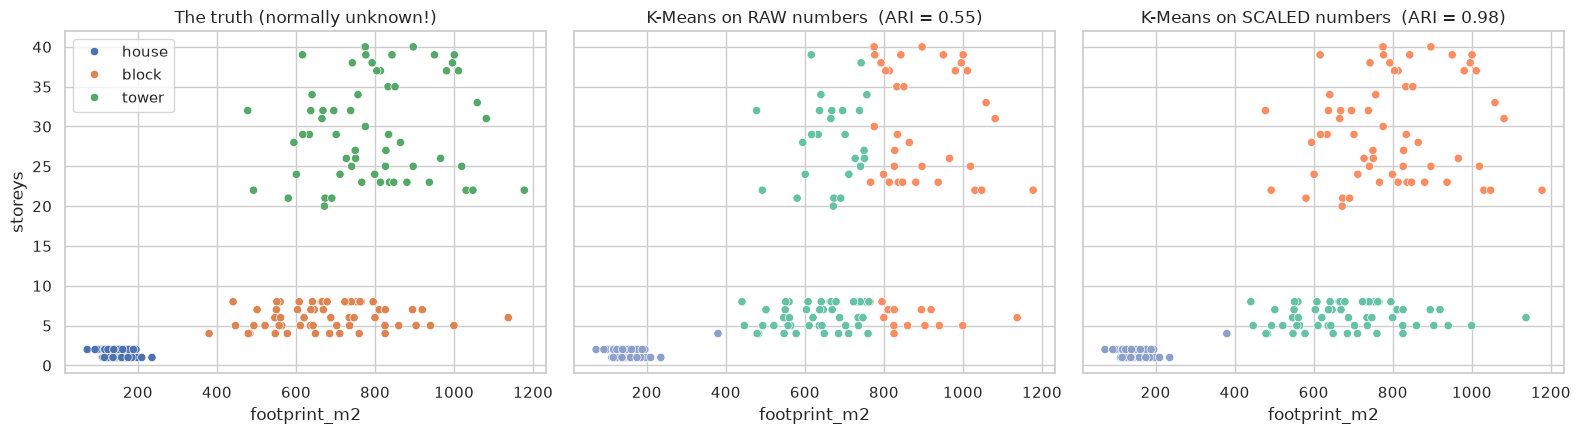

In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score

rng = np.random.default_rng(RANDOM_STATE)

# Three made-up building types, 60 buildings each: (footprint area in m², number of storeys)
houses = np.column_stack([rng.normal(150, 40, 60), rng.integers(1, 3, 60)])
blocks = np.column_stack([rng.normal(700, 150, 60), rng.integers(4, 9, 60)])
towers = np.column_stack([rng.normal(800, 150, 60), rng.integers(20, 41, 60)])

toy_buildings = pd.DataFrame(np.vstack([houses, blocks, towers]), columns=["footprint_m2", "storeys"])
true_type = np.repeat(["house", "block", "tower"], 60)   # we know the truth only because we made the data up

# K-Means with 3 groups, once on the raw numbers and once on standardised numbers
labels_raw = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit_predict(toy_buildings)
toy_scaled = StandardScaler().fit_transform(toy_buildings)
labels_scaled = KMeans(n_clusters=3, n_init=10, random_state=RANDOM_STATE).fit_predict(toy_scaled)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
sns.scatterplot(data=toy_buildings, x="footprint_m2", y="storeys", hue=true_type, ax=axes[0])
axes[0].set_title("The truth (normally unknown!)")
sns.scatterplot(data=toy_buildings, x="footprint_m2", y="storeys", hue=labels_raw, palette="Set2", ax=axes[1], legend=False)
axes[1].set_title(f"K-Means on RAW numbers  (ARI = {adjusted_rand_score(true_type, labels_raw):.2f})")
sns.scatterplot(data=toy_buildings, x="footprint_m2", y="storeys", hue=labels_scaled, palette="Set2", ax=axes[2], legend=False)
axes[2].set_title(f"K-Means on SCALED numbers  (ARI = {adjusted_rand_score(true_type, labels_scaled):.2f})")
plt.tight_layout()
save_fig("01_scaling_matters")
plt.show()

On the raw numbers, K-Means cuts the data **by area only** (vertical cuts), mixing blocks and towers. After scaling, storeys get a fair vote and the three types appear.

The **ARI** (*adjusted Rand index*) in the titles compares the clusters with the true types: **1 = perfect match, 0 = no better than random**. We can only compute it here because we invented the data; section 1.2 explains what to do in real projects.

⚠️ **Watch out:** scaling is **not optional** for K-Means, hierarchical clustering, DBSCAN, PCA, t-SNE and UMAP. Forget it and the column with the biggest numbers decides alone. As on Day 2, you can glue the scaler and the algorithm together: `make_pipeline(StandardScaler(), KMeans(n_clusters=3))`.

🤔 **Think about it:** scaling gives every column the **same** weight. Is that always what you want? If you think orientation matters less than height for your question, you could drop it, or give it a smaller weight. **Choosing the columns is choosing what "similar" means.** We will see this very clearly in Application A.

### Why the biggest numbers win: comparing the variance of each feature

The **variance** measures how much a column spreads around its mean (the **standard deviation**, std, is its square root, in the column's own unit). It matters here because, for two random examples, the expected squared difference in a column is exactly **twice its variance**. So **each column's share of the total variance is roughly its share of the squared Euclidean distance**: its "vote" in every distance-based method.

To compare spread across columns with different units, the **coefficient of variation** (std ÷ mean) is a unit-free alternative: it says how large the spread is *relative to the typical value*.

In [5]:
scaled_df = pd.DataFrame(toy_scaled, columns=toy_buildings.columns)

variance_table = pd.DataFrame({
    "mean": toy_buildings.mean(),
    "std": toy_buildings.std(ddof=0),
    "coefficient of variation": toy_buildings.std(ddof=0) / toy_buildings.mean(),
    "variance (raw)": toy_buildings.var(ddof=0),
    "share of distance (raw)": toy_buildings.var(ddof=0) / toy_buildings.var(ddof=0).sum(),
    "variance (scaled)": scaled_df.var(ddof=0),
    "share of distance (scaled)": scaled_df.var(ddof=0) / scaled_df.var(ddof=0).sum(),
})
variance_table.round(3)

,mean,std,coefficient of variation,variance (raw),share of distance (raw),variance (scaled),share of distance (scaled)
footprint_m2,543.615,306.205,0.563,"93,761.345",0.998,1.000,0.500
storeys,12.450,12.929,1.039,167.170,0.002,1.000,0.500


Figure saved to figures/01b_feature_variance.png


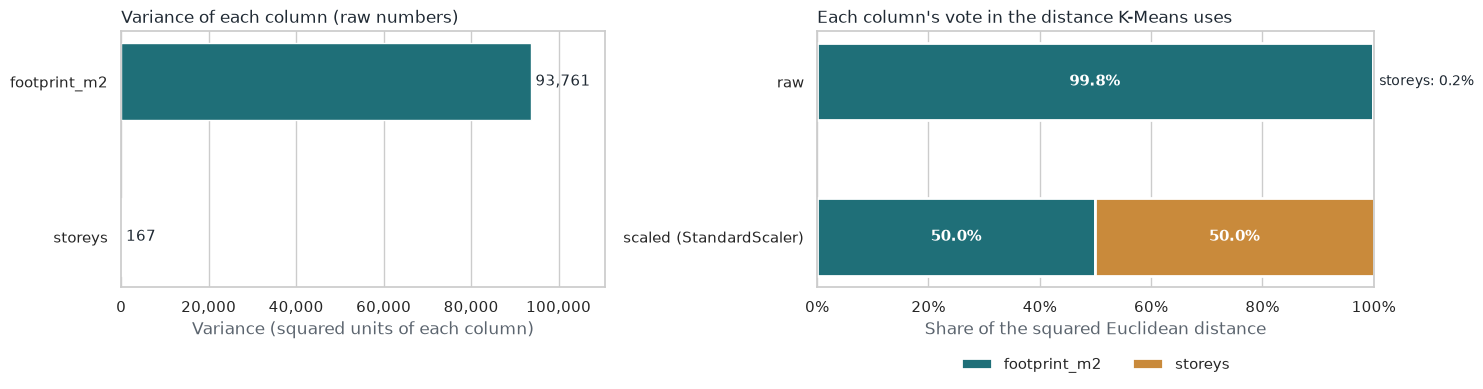

In [6]:
# One colour per column, used in both panels (values are always printed: colour is never the only cue)
COLUMN_COLORS = {"footprint_m2": "#1F6F78", "storeys": "#C98A3B"}
INK, MUTED_INK = "#1F2933", "#5B646E"

fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1, 1.15]})

# Left: raw variance of each column, on a normal (linear) scale
ax = axes[0]
raw_variance = variance_table["variance (raw)"]
ax.barh(raw_variance.index, raw_variance.values, height=0.5,
        color=[COLUMN_COLORS[c] for c in raw_variance.index])
for y, (name, value) in enumerate(raw_variance.items()):
    ax.text(value + raw_variance.max() * 0.01, y, f"{value:,.0f}", va="center", color=INK, fontsize=11)
ax.set_xlim(0, raw_variance.max() * 1.18)
ax.invert_yaxis()
ax.set_title("Variance of each column (raw numbers)", loc="left", color=INK)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.StrMethodFormatter("{x:,.0f}"))
ax.set_xlabel("Variance (squared units of each column)", color=MUTED_INK)
ax.grid(axis="y", visible=False)

# Right: each column's share of the squared distance, before and after scaling
ax = axes[1]
shares = pd.DataFrame({"raw": variance_table["share of distance (raw)"],
                       "scaled (StandardScaler)": variance_table["share of distance (scaled)"]}).T
left = np.zeros(len(shares))
for column in shares.columns:
    values = shares[column].values
    ax.barh(shares.index, values, left=left, height=0.5, color=COLUMN_COLORS[column],
            edgecolor="white", linewidth=2, label=column)
    for y, (start, value) in enumerate(zip(left, values)):
        if value >= 0.05:   # label inside the bar when it is wide enough
            ax.text(start + value / 2, y, f"{value:.1%}", ha="center", va="center", color="white", fontsize=11,
                    fontweight="bold")
        else:               # otherwise just after the end of the bar
            ax.text(1.01, y, f"{column}: {value:.1%}", va="center", color=INK, fontsize=10)
    left += values
ax.set_xlim(0, 1)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Each column's vote in the distance K-Means uses", loc="left", color=INK)
ax.set_xlabel("Share of the squared Euclidean distance", color=MUTED_INK)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=2, frameon=False)
ax.grid(axis="y", visible=False)

plt.tight_layout()
save_fig("01b_feature_variance")
plt.show()

The table puts numbers on what the plot showed:
- **Raw:** the variance of `footprint_m2` (about 94,000) is about **560 times** that of `storeys` (about 167). Variance is measured in *squared* units, which makes it hard to read on its own; the standard deviation (306 m² vs 13 storeys) is back in the column's own unit. Footprint gets **99.8%** of the distance, storeys **0.2%**: K-Means practically ignores the number of storeys.
- **Coefficient of variation:** relative to its typical value, `storeys` actually varies **more** than the footprint (1.04 vs 0.56). The raw variance hides this because it depends on the unit: the same footprints in km² would have a tiny variance.
- **Scaled:** after `StandardScaler` both columns have variance 1 and get **50% / 50%** of the distance. Every column has the same vote.

### Which variance treatment, when?

`StandardScaler` is the default, but it is not the only option. This notebook uses four strategies, each on purpose:

| Situation | Treatment | Where in this notebook |
|---|---|---|
| Columns in **different units or ranges** (m², storeys, ratios, codes) | **Standardise each column** (`StandardScaler`: mean 0, variance 1) | 1.1, 2.4, 3.1, Application A, Application D |
| A **skewed** column: a few huge values (prices, areas, populations) | **Log-transform** it first, then standardise | Application D (`price_per_m2`) |
| Each **row** is a profile and you want to compare **shapes, not sizes** | **Normalise each row** (`Normalizer`: divide each row by its total) | Application B (daily load curves) |
| All columns **share one unit** and their size is meaningful | **No scaling** | Application C (x, y, z in metres) |

💡 **Tip:** two other scalers you will meet: `MinMaxScaler` squeezes each column into 0–1 (sensitive to a single extreme value), and `RobustScaler` uses the median and the interquartile range instead of the mean and the variance, so **outliers** don't dominate the scaling.

## 1.2 No ground truth: how do we judge the result?

Without answers we cannot compute an error. Instead we use three kinds of checks:

| Check | Question it answers | Tools |
|---|---|---|
| **Internal metrics** | Are the clusters compact and well separated? | **Inertia** (sum of squared distances to the cluster centre, lower = tighter), **silhouette score** (−1 to 1, higher = better separated), Davies–Bouldin (lower = better) |
| **External metrics** | Do the clusters match some known labels? (only when labels exist for checking) | **Adjusted Rand index (ARI)**: 1 = perfect, 0 = random |
| **Domain knowledge** | Do the groups **mean** something? Can I give each one a name? | Cluster profiles (averages per cluster), plots, cross-tables with variables we did **not** use |

The **silhouette** of one example compares two distances:
- **a** = the average distance to the other members of **its own** cluster (how well it fits in)
- **b** = the average distance to the members of the **nearest other** cluster (how close the neighbours are)

$$s = \frac{b - a}{\max(a, b)}$$

Close to **1**: the point sits well inside its cluster. Around **0**: it lies on the border between two clusters. **Negative**: it is probably in the wrong cluster. The **silhouette score** is the average over all points.

⚠️ **Watch out:** the metrics help, but the **last word belongs to interpretation**. A clustering with a modest silhouette that splits buildings into meaningful groups is more useful than a "perfect" score that separates nonsense. We will meet exactly this situation in Application B.

## 1.3 The curse of dimensionality

Our datasets have 8, 24, or even more columns, so every example is a point in an 8-, 24-dimensional space. Our intuition, trained on 2D drawings and 3D buildings, fails there. One strange effect: **as dimensions grow, all points become almost equally far from each other**, so "the nearest neighbour" means less and less.

The experiment below throws 500 random points into spaces of increasing dimension and measures how much the farthest point is farther than the nearest one.

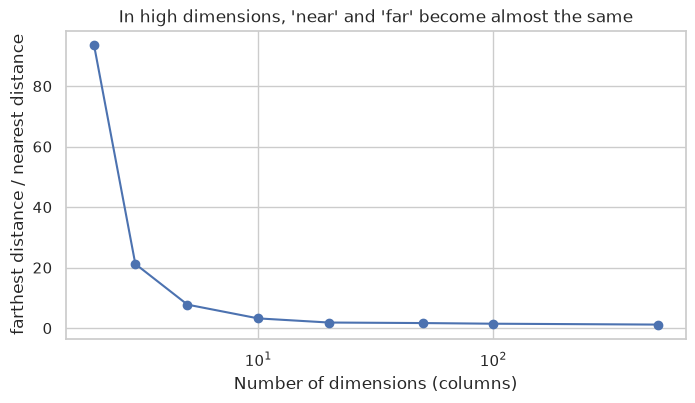

   2 dimensions: the farthest point is   93.7 times as far as the nearest
   3 dimensions: the farthest point is   21.2 times as far as the nearest
   5 dimensions: the farthest point is    7.8 times as far as the nearest
  10 dimensions: the farthest point is    3.2 times as far as the nearest
  20 dimensions: the farthest point is    1.9 times as far as the nearest
  50 dimensions: the farthest point is    1.7 times as far as the nearest
 100 dimensions: the farthest point is    1.5 times as far as the nearest
 500 dimensions: the farthest point is    1.2 times as far as the nearest


In [7]:
from sklearn.metrics import pairwise_distances

dimensions = [2, 3, 5, 10, 20, 50, 100, 500]
contrast = []
for d in dimensions:
    points = rng.random((500, d))                         # 500 random points in d dimensions
    dist = pairwise_distances(points[:1], points[1:])[0]  # distances from the first point to all others
    contrast.append(dist.max() / dist.min())

plt.figure(figsize=(8, 4))
plt.plot(dimensions, contrast, marker="o")
plt.xscale("log")
plt.xlabel("Number of dimensions (columns)")
plt.ylabel("farthest distance / nearest distance")
plt.title("In high dimensions, 'near' and 'far' become almost the same")
plt.show()

for d, c in zip(dimensions, contrast):
    print(f"{d:>4} dimensions: the farthest point is {c:6.1f} times as far as the nearest")

Figure saved to figures/02c_curse_of_dimensionality.png


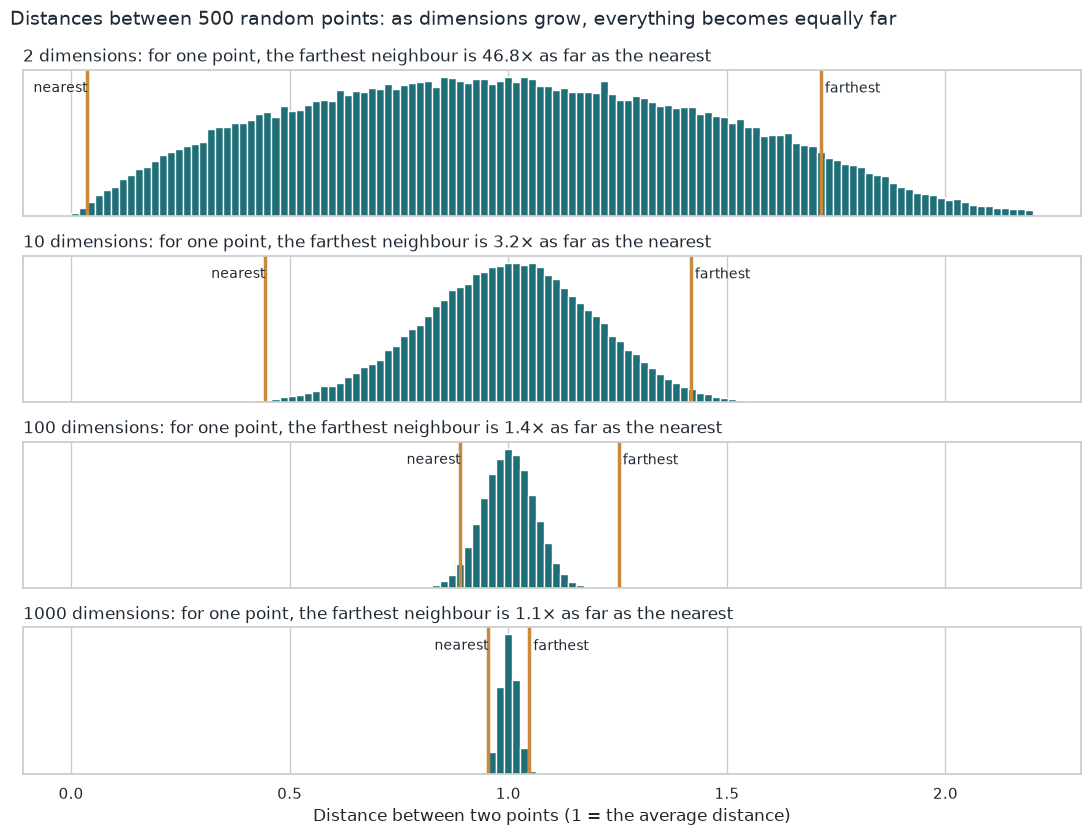

In [8]:
from scipy.spatial.distance import pdist

# The same experiment, drawn: how are the distances between 500 random points distributed?
# (new random points, so the exact ratios differ a little from the cell above: the trend is what matters)
demo_rng = np.random.default_rng(RANDOM_STATE)
dims_to_show = [2, 10, 100, 1000]
TEAL, OCHRE, INK = "#1F6F78", "#C98A3B", "#1F2933"

fig, axes = plt.subplots(len(dims_to_show), 1, figsize=(11, 8.5), sharex=True)
for ax, d in zip(axes, dims_to_show):
    points = demo_rng.random((500, d))
    all_distances = pdist(points)                          # every pair of points
    mean_distance = all_distances.mean()
    from_one_point = pairwise_distances(points[:1], points[1:])[0] / mean_distance
    nearest, farthest = from_one_point.min(), from_one_point.max()

    ax.hist(all_distances / mean_distance, bins=120, range=(0, 2.2), color=TEAL)
    for x, label in [(nearest, "nearest"), (farthest, "farthest")]:
        ax.axvline(x, color=OCHRE, lw=2.5)
        ax.text(x, 0.92, f" {label}", transform=ax.get_xaxis_transform(), color=INK, fontsize=10, va="top",
                ha="left" if label == "farthest" else "right")
    ax.set_title(f"{d} dimensions: for one point, the farthest neighbour is {farthest / nearest:.1f}× as far as the nearest",
                 loc="left", fontsize=12, color=INK)
    ax.set_yticks([])
    ax.grid(axis="y", visible=False)

axes[-1].set_xlabel("Distance between two points (1 = the average distance)")
fig.suptitle("Distances between 500 random points: as dimensions grow, everything becomes equally far",
             x=0.01, ha="left", fontsize=14, color=INK)
plt.tight_layout()
save_fig("02c_curse_of_dimensionality")
plt.show()

In 2D the farthest point is many times farther than the nearest; with hundreds of dimensions everything is at roughly the same distance. Distance-based methods (clustering, KNN) suffer from this. **Dimensionality reduction** (section 3) fights it by keeping only the few directions that carry real information. It also lets us **see** the data, since we can only draw 2 or 3 dimensions.

# 2. Clustering algorithms

We meet the three algorithms of the syllabus on small **toy datasets** first, where we can see the result with our own eyes. Then we compare them side by side.

💡 **Tip – see it for yourself:** [Clustering Visualizer](https://clustering-visualizer.web.app/) is an interactive page where you place points on a canvas and watch **K-Means**, **hierarchical clustering** and **DBSCAN** (the three algorithms of today) group them, step by step. It also includes **Mean Shift**, which we don't cover: like K-Means it moves centres around, but it finds the number of clusters by itself by climbing towards the densest areas. Try it after reading 2.1–2.3: draw round blobs, then long curved shapes, then a few lonely points far away, and see which algorithm copes with which. It is the hands-on version of the comparison in section 2.4.

## 2.1 K-Means

**Intuition:** you want to place **k** tool sheds on a construction site so that every worker walks as little as possible to the nearest shed.
1. Put the k sheds (the **centroids**) somewhere at random.
2. Every worker goes to the **nearest** shed: these are the clusters.
3. Move each shed to the **centre** (the mean position) of its workers.
4. Repeat steps 2–3 until the sheds stop moving.

| | |
|---|---|
| **Key parameter** | `n_clusters` (k): **you** must choose it |
| **Other parameters** | `n_init`: how many random starts (the best one is kept); `random_state` |
| **Strengths** | Simple, fast, scales to millions of points, every cluster has a readable "average member" (the centroid) |
| **Weaknesses** | You must choose k; assumes round, similar-sized clusters; sensitive to outliers and to scaling; every point is forced into a cluster |

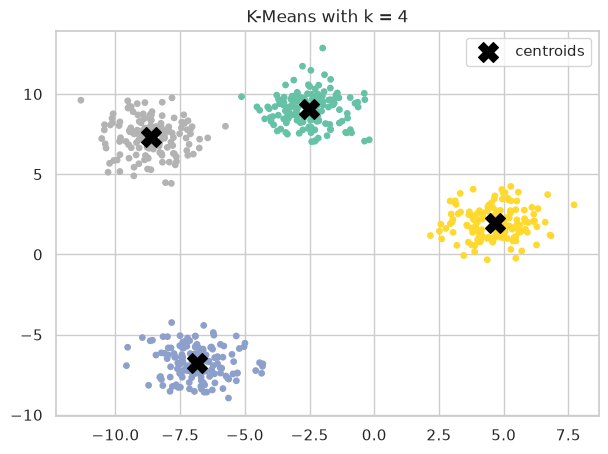

In [9]:
from sklearn.datasets import make_blobs

# 600 points in 4 groups (we pretend we don't know there are 4)
X_blobs, y_blobs = make_blobs(n_samples=600, centers=4, cluster_std=1.0, random_state=RANDOM_STATE)

kmeans = KMeans(n_clusters=4, n_init=10, random_state=RANDOM_STATE)
blob_labels = kmeans.fit_predict(X_blobs)    # fit = find the centroids, predict = assign each point

plt.figure(figsize=(7, 5))
plt.scatter(X_blobs[:, 0], X_blobs[:, 1], c=blob_labels, cmap="Set2", s=15)
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            c="black", marker="X", s=200, label="centroids")
plt.title("K-Means with k = 4")
plt.legend()
plt.show()

### Choosing k: the elbow and the silhouette

In real data we don't know k. Two common tools:
- **Elbow method:** plot the **inertia** for k = 1, 2, 3… Inertia always decreases with more clusters (with k = number of points it is 0!), but at some point the gain becomes small: the "elbow" of the curve is a good k.
- **Silhouette:** compute the silhouette score for each k and pick the highest.

They don't always agree. Use them as **hints**, then check whether the groups make sense.

Figure saved to figures/02_choosing_k.png


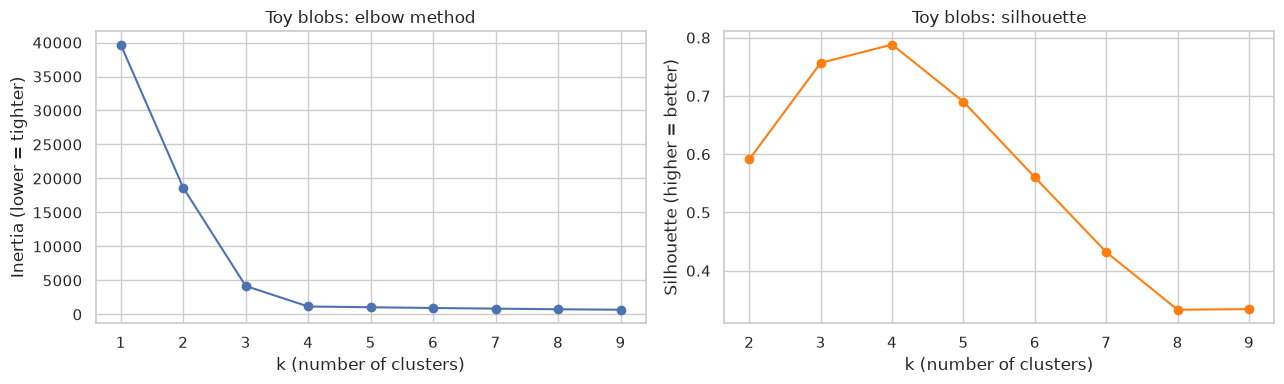

,inertia,silhouette
k,,
1,"39,698.269",NaN
2,"18,637.866",0.591
3,"4,178.870",0.757
4,"1,160.275",0.788
5,"1,045.649",0.690
6,939.185,0.560
7,843.967,0.432
8,749.712,0.333
9,684.729,0.334


In [10]:
from sklearn.metrics import silhouette_score


def scan_k(X, k_values, random_state=RANDOM_STATE):
    # Fit K-Means for every k and return a table with inertia and silhouette
    rows = []
    for k in k_values:
        model = KMeans(n_clusters=k, n_init=10, random_state=random_state).fit(X)
        silhouette = silhouette_score(X, model.labels_) if k > 1 else np.nan
        rows.append({"k": k, "inertia": model.inertia_, "silhouette": silhouette})
    return pd.DataFrame(rows).set_index("k")


def plot_k_scan(scan, title):
    # Draw the elbow curve and the silhouette curve next to each other
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    axes[0].plot(scan.index, scan["inertia"], marker="o")
    axes[0].set_title(f"{title}: elbow method")
    axes[0].set_xlabel("k (number of clusters)")
    axes[0].set_ylabel("Inertia (lower = tighter)")
    axes[1].plot(scan.index, scan["silhouette"], marker="o", color="tab:orange")
    axes[1].set_title(f"{title}: silhouette")
    axes[1].set_xlabel("k (number of clusters)")
    axes[1].set_ylabel("Silhouette (higher = better)")
    plt.tight_layout()


blob_scan = scan_k(X_blobs, range(1, 10))
plot_k_scan(blob_scan, "Toy blobs")
save_fig("02_choosing_k")
plt.show()
blob_scan

Both tools point to **k = 4**: the inertia curve bends sharply there, and the silhouette peaks. On toy data this is easy; on real data the curves are often smoother and the choice becomes a judgement call.

### What the metrics actually measure

We have used inertia and the silhouette as black boxes. Let's open them up, on the same toy blobs with k = 4.

- **Inertia** = the sum of the **squared distances** from every point to its own centroid: the total length² of the grey lines on the left. Lower = tighter clusters.
- **Silhouette** of one point = $(b - a) / \max(a, b)$, where **a** is its average distance to the other members of its own cluster and **b** its average distance to the members of the nearest other cluster. The right plot shows the silhouette of **every point**, sorted and grouped by cluster: a **silhouette plot**.

Figure saved to figures/02b_inertia_and_silhouette.png


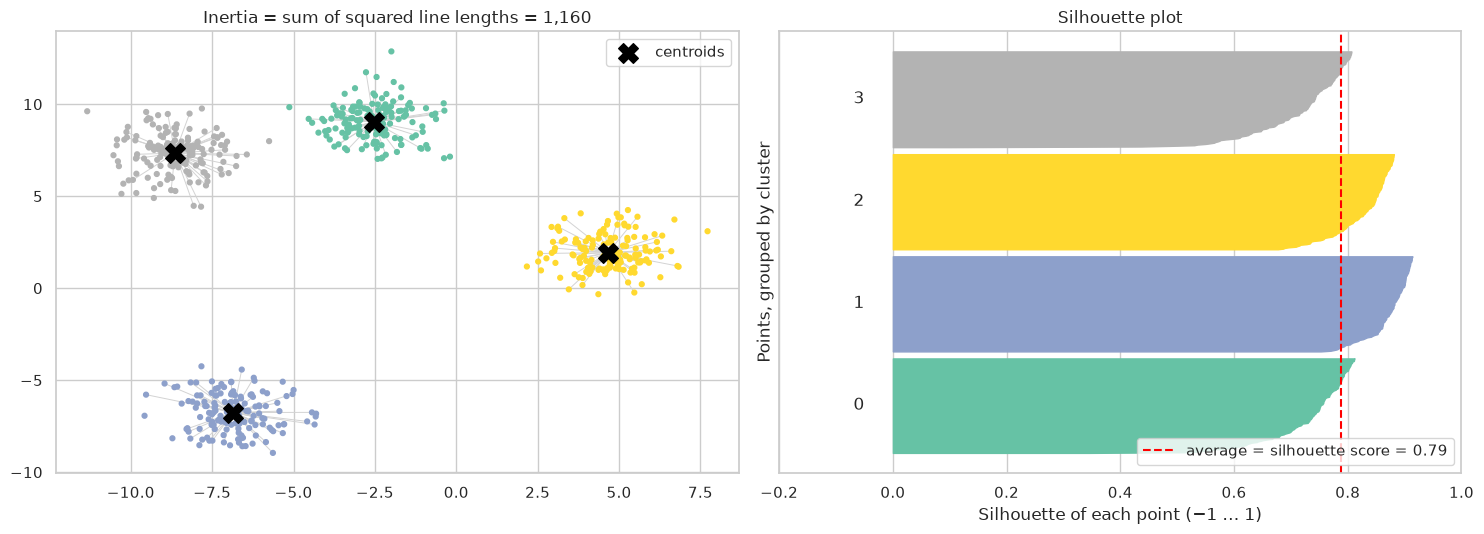

Average silhouette per cluster: {0: 0.73, 1: 0.87, 2: 0.83, 3: 0.72}
Points with a negative silhouette (probably in the wrong cluster): 0


In [11]:
from sklearn.metrics import silhouette_samples

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# Left: inertia = the sum of the squared lengths of these lines
ax = axes[0]
centres = kmeans.cluster_centers_
for point, label in zip(X_blobs[::3], blob_labels[::3]):      # every 3rd point, to keep it readable
    ax.plot([point[0], centres[label, 0]], [point[1], centres[label, 1]], color="lightgrey", lw=0.7, zorder=1)
ax.scatter(X_blobs[:, 0], X_blobs[:, 1], c=blob_labels, cmap="Set2", s=12, zorder=2)
ax.scatter(centres[:, 0], centres[:, 1], c="black", marker="X", s=200, zorder=3, label="centroids")
ax.set_title(f"Inertia = sum of squared line lengths = {kmeans.inertia_:,.0f}")
ax.legend()

# Right: silhouette plot, one horizontal line per point
ax = axes[1]
point_silhouettes = silhouette_samples(X_blobs, blob_labels)
average = point_silhouettes.mean()
y_start = 0
for cluster in range(4):
    values = np.sort(point_silhouettes[blob_labels == cluster])
    ax.fill_betweenx(np.arange(y_start, y_start + len(values)), 0, values, color=plt.cm.Set2(cluster / 3))   # same colours as the left plot
    ax.text(-0.05, y_start + len(values) / 2, str(cluster), ha="right", va="center")
    y_start += len(values) + 10                                   # a small gap between clusters
ax.axvline(average, color="red", linestyle="--", label=f"average = silhouette score = {average:.2f}")
ax.set_xlim(-0.2, 1)
ax.set_yticks([])
ax.set_xlabel("Silhouette of each point (−1 … 1)")
ax.set_ylabel("Points, grouped by cluster")
ax.set_title("Silhouette plot")
ax.legend(loc="lower right")

plt.tight_layout()
save_fig("02b_inertia_and_silhouette")
plt.show()

print("Average silhouette per cluster:",
      pd.Series(point_silhouettes).groupby(blob_labels).mean().round(2).to_dict())
print(f"Points with a negative silhouette (probably in the wrong cluster): {(point_silhouettes < 0).sum()}")

How to read a silhouette plot:
- Each coloured band is one cluster; its **thickness** is the number of points, and each point's **length** is its silhouette.
- **Long bands that pass the red average line** = points that sit well inside their cluster. Here every cluster is between **0.72 and 0.87** on average, and **no point is negative**: four clean groups.
- The two clusters at the top-left of the scatter plot (the closest pair of blobs) have the **lowest** averages (0.72–0.73): their points are a little nearer to the neighbouring cluster.
- Warning signs: a band that **ends before the average line**, a tail of **negative** values (points that are closer to another cluster than to their own), or bands of very **different thickness** when you expected similar groups.

💡 **Tip:** draw the silhouette plot for two or three candidate values of k. It shows *which* cluster is weak, something the single average score hides.

### Two more internal metrics

scikit-learn has two other common scores. Like the silhouette, they compare **how compact** the clusters are with **how far apart** they are, each in its own way:

| Metric | Idea | Better when | Range |
|---|---|---|---|
| **Inertia** | Total squared distance to the own centroid | lower (but it always drops with more k) | 0 … ∞ |
| **Silhouette** | For every point: own cluster vs nearest other cluster | **higher** | −1 … 1 |
| **Davies–Bouldin** | For every cluster: its spread compared with the distance to its most similar cluster, averaged | **lower** | 0 … ∞ |
| **Calinski–Harabasz** | Spread *between* clusters divided by spread *within* clusters | **higher** | 0 … ∞ |

In [12]:
from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score

rows = []
for k in range(2, 9):
    model = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_blobs)
    rows.append({"k": k,
                 "inertia (lower)": model.inertia_,
                 "silhouette (higher)": silhouette_score(X_blobs, model.labels_),
                 "Davies–Bouldin (lower)": davies_bouldin_score(X_blobs, model.labels_),
                 "Calinski–Harabasz (higher)": calinski_harabasz_score(X_blobs, model.labels_)})
internal_metrics = pd.DataFrame(rows).set_index("k")
internal_metrics.round(2)

,inertia (lower),silhouette (higher),Davies–Bouldin (lower),Calinski–Harabasz (higher)
k,,,,
2,"18,637.870",0.590,0.530,675.730
3,"4,178.870",0.760,0.350,"2,537.180"
4,"1,160.270",0.790,0.300,"6,598.620"
5,"1,045.650",0.690,0.600,"5,498.570"
6,939.180,0.560,0.840,"4,902.740"
7,843.970,0.430,1.040,"4,551.200"
8,749.710,0.330,1.160,"4,393.600"


On clean toy data **all three scores agree on k = 4** (highest silhouette, lowest Davies–Bouldin, highest Calinski–Harabasz), and the inertia shows its elbow there. On real data they often disagree; when they do, report them side by side and let interpretation decide.

⚠️ **Watch out:** all internal metrics **prefer round, compact, well-separated clusters**, because they are built on distances to centres or averages. They would score DBSCAN's correct moons *lower* than K-Means' wrong straight cut. Use them to compare k for the **same algorithm**, not to crown an algorithm.

### The adjusted Rand index (ARI): comparing two groupings

The ARI is not about compactness. It compares **two labelings of the same points** and asks: *for every pair of points, do both labelings agree on whether the two belong together?*

- The plain **Rand index** is the share of pairs on which they agree.
- The **adjusted** version subtracts what random labels would score, so **0 = no better than chance** and **1 = identical groupings**. Cluster *numbers* don't matter, only who is grouped with whom.

Here are six labelings of 12 points that really form three groups of four:

In [13]:
from sklearn.metrics import rand_score

true_groups = np.repeat([0, 1, 2], 4)
labelings = {
    "same groups, other numbers": np.repeat([2, 0, 1], 4),
    "one point in the wrong group": np.array([0, 0, 0, 1, 1, 1, 1, 1, 2, 2, 2, 2]),
    "two groups merged": np.repeat([0, 0, 1], 4),
    "everything in one cluster": np.zeros(12, dtype=int),
    "every point alone": np.arange(12),
    "random labels": np.random.default_rng(RANDOM_STATE).integers(0, 3, 12),
}
pd.DataFrame({
    "labels": [" ".join(map(str, labels)) for labels in labelings.values()],
    "Rand index": [rand_score(true_groups, labels) for labels in labelings.values()],
    "ARI": [adjusted_rand_score(true_groups, labels) for labels in labelings.values()],
}, index=labelings.keys()).round(2)

,labels,Rand index,ARI
"same groups, other numbers",2 2 2 2 0 0 0 0 1 1 1 1,1.000,1.000
one point in the wrong group,0 0 0 1 1 1 1 1 2 2 2 2,0.890,0.740
two groups merged,0 0 0 0 0 0 0 0 1 1 1 1,0.760,0.520
everything in one cluster,0 0 0 0 0 0 0 0 0 0 0 0,0.270,0.000
every point alone,0 1 2 3 4 5 6 7 8 9 10 11,0.730,0.000
random labels,0 2 1 1 1 2 0 2 0 0 1 2,0.550,-0.150


- **Other numbers, same groups → ARI 1**: the labels are just names.
- **"Every point alone"** gets a plain Rand index of **0.73**, because most pairs *are* correctly separated. The ARI corrects this to **0**: that is why we always use the **adjusted** version.
- **Random labels** can even go **below 0**.

We use the ARI in three ways today: against **known labels** when we have them for checking (toy data, the 12 building shapes, the point cloud), **between two algorithms** (do K-Means and ward agree?), and for **stability** (does a different seed or subsample give the same groups?).

## 2.2 Hierarchical (agglomerative) clustering

**Intuition:** build a **family tree** of the data, bottom-up.
1. Start with every point as its own cluster.
2. Merge the **two closest** clusters.
3. Repeat until everything is one big cluster.

The result is a **dendrogram**: a tree where the **height** of each merge shows how different the two merged groups were. You choose the number of clusters **after** the fact, by cutting the tree at some height. That is very attractive when you don't know k in advance.

"Closest clusters" needs a definition, the **linkage**:

| Linkage | Distance between two clusters = | Tends to give |
|---|---|---|
| `ward` (default) | Increase in within-cluster variance if merged | Compact, similar-sized clusters (like K-Means) |
| `average` | Average distance between all pairs of points | A balance |
| `complete` | Distance between the two **farthest** points | Compact clusters |
| `single` | Distance between the two **nearest** points | Long "chains"; can follow odd shapes but is very sensitive to noise |

| | |
|---|---|
| **Strengths** | No need to fix k beforehand; the dendrogram is a great **explanation** tool; works with any distance |
| **Weaknesses** | Slow on large data (it compares all pairs: fine for thousands of rows, not millions); a merge can never be undone |

We draw the dendrogram with `scipy` and do the actual clustering with scikit-learn's `AgglomerativeClustering`. Here on 30 points so the tree stays readable.

Figure saved to figures/03_dendrogram_toy.png


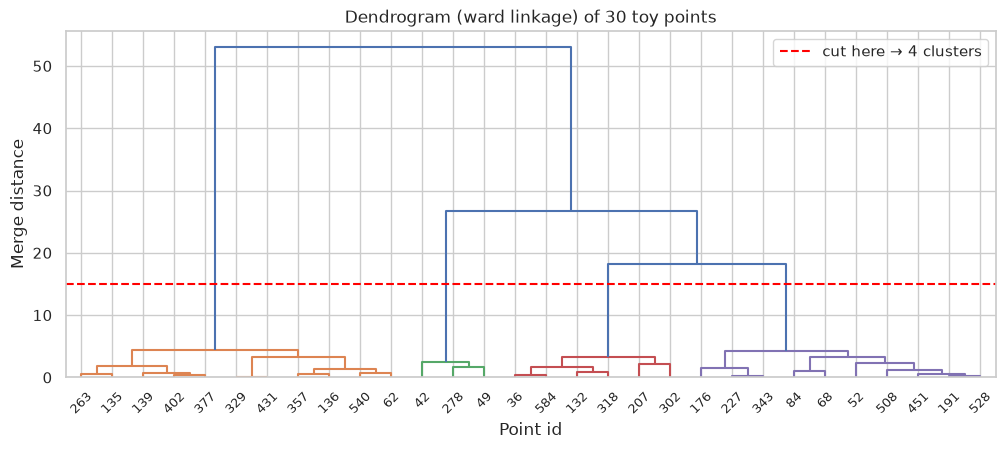

Cluster of each of the 30 points: [2 3 2 3 1 0 1 1 1 1 1 0 2 0 0 0 3 0 0 3 0 1 1 0 3 1 0 3 0 1]


In [14]:
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering

# A small sample keeps the tree readable
sample_idx = rng.choice(len(X_blobs), size=30, replace=False)
X_small = X_blobs[sample_idx]

tree = linkage(X_small, method="ward")   # the full merge history

plt.figure(figsize=(12, 4.5))
dendrogram(tree, labels=sample_idx, leaf_font_size=9, color_threshold=15)
plt.axhline(15, color="red", linestyle="--", label="cut here → 4 clusters")
plt.title("Dendrogram (ward linkage) of 30 toy points")
plt.xlabel("Point id")
plt.ylabel("Merge distance")
plt.legend()
save_fig("03_dendrogram_toy")
plt.show()

# The same thing with scikit-learn: ask directly for 4 clusters
agglo = AgglomerativeClustering(n_clusters=4, linkage="ward")
print("Cluster of each of the 30 points:", agglo.fit_predict(X_small))

Read the tree from the bottom: points that merge low down are very similar. The four long vertical branches show four well separated groups. Cutting where the branches are longest (the red line) gives 4 clusters.

## 2.3 DBSCAN

**DBSCAN** (*Density-Based Spatial Clustering of Applications with Noise*) does not look for centres. It looks for **dense regions**.

**Intuition:** a crowd in a square. People standing close together form groups; someone standing alone is not part of any group.
- `eps`: the radius of a "neighbourhood" (how close counts as close).
- `min_samples`: how many neighbours inside `eps` make a point a **core point** (in the middle of the crowd).
- Core points that are within `eps` of each other are chained into the same cluster; **border** points are close to a core point; everything else is **noise** (label **−1**).

| | |
|---|---|
| **Key parameters** | `eps` and `min_samples` (no k!) |
| **Strengths** | Finds the number of clusters by itself; clusters of **any shape**; marks outliers as noise instead of forcing them into a group |
| **Weaknesses** | `eps` is hard to choose and depends on scaling; struggles when clusters have very **different densities** |

💡 **Tip:** scikit-learn also has **HDBSCAN** (`sklearn.cluster.HDBSCAN`), a newer version that tries all `eps` values at once and copes better with different densities. Worth trying when DBSCAN struggles.

Let's use two "moons" (curved, non-round clusters) with some random noise points added.

In [15]:
from sklearn.datasets import make_moons
from sklearn.cluster import DBSCAN

X_moons, y_moons = make_moons(n_samples=500, noise=0.06, random_state=RANDOM_STATE)
noise_points = rng.uniform(low=[-1.5, -1.0], high=[2.5, 1.5], size=(40, 2))
X_moons = np.vstack([X_moons, noise_points])
y_moons = np.concatenate([y_moons, np.full(40, -1)])   # -1 = noise in the "truth" too

### Choosing `eps`: the k-distance plot

For every point, measure the distance to its `min_samples`-th nearest neighbour and sort these distances. Points inside clusters have small distances; noise points have large ones. The curve has a **knee** where it shoots up: a good `eps` is just below the knee.

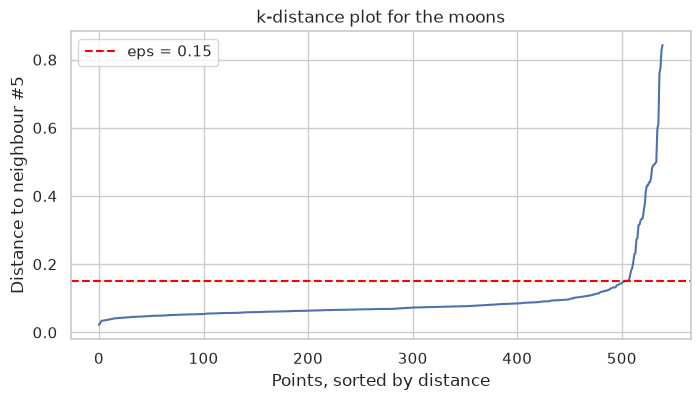

In [16]:
from sklearn.neighbors import NearestNeighbors


def k_distance_plot(X, k, title):
    # Sorted distance from every point to its k-th nearest neighbour
    neighbours = NearestNeighbors(n_neighbors=k + 1).fit(X)   # +1 because each point is its own nearest neighbour
    distances, _ = neighbours.kneighbors(X)
    plt.figure(figsize=(8, 4))
    plt.plot(np.sort(distances[:, -1]))
    plt.xlabel("Points, sorted by distance")
    plt.ylabel(f"Distance to neighbour #{k}")
    plt.title(title)


MIN_SAMPLES = 5
k_distance_plot(X_moons, MIN_SAMPLES, "k-distance plot for the moons")
plt.axhline(0.15, color="red", linestyle="--", label="eps = 0.15")
plt.legend()
plt.show()

DBSCAN found 2 clusters and 28 noise points


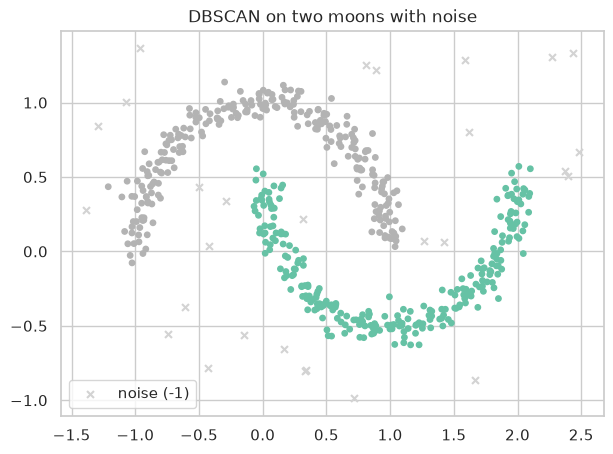

In [17]:
dbscan = DBSCAN(eps=0.15, min_samples=MIN_SAMPLES)
moon_labels = dbscan.fit_predict(X_moons)

n_clusters = len(set(moon_labels)) - (1 if -1 in moon_labels else 0)
print(f"DBSCAN found {n_clusters} clusters and {(moon_labels == -1).sum()} noise points")

plt.figure(figsize=(7, 5))
is_noise = moon_labels == -1
plt.scatter(X_moons[~is_noise, 0], X_moons[~is_noise, 1], c=moon_labels[~is_noise], cmap="Set2", s=15)
plt.scatter(X_moons[is_noise, 0], X_moons[is_noise, 1], c="lightgrey", marker="x", s=25, label="noise (-1)")
plt.title("DBSCAN on two moons with noise")
plt.legend()
plt.show()

DBSCAN finds the two curved shapes **and** sets most of the random points aside as noise. Nobody told it there were two clusters.

## 2.4 Side by side: which algorithm for which shape?

Same three algorithms, three kinds of data:
- **blobs:** round, well separated groups (the easy case)
- **moons + noise:** curved shapes and outliers
- **different densities:** one tight group next to a spread-out one

The title of each panel shows the ARI against the true groups (1 = perfect). Grey crosses are points DBSCAN called noise.

Figure saved to figures/04_clustering_comparison.png


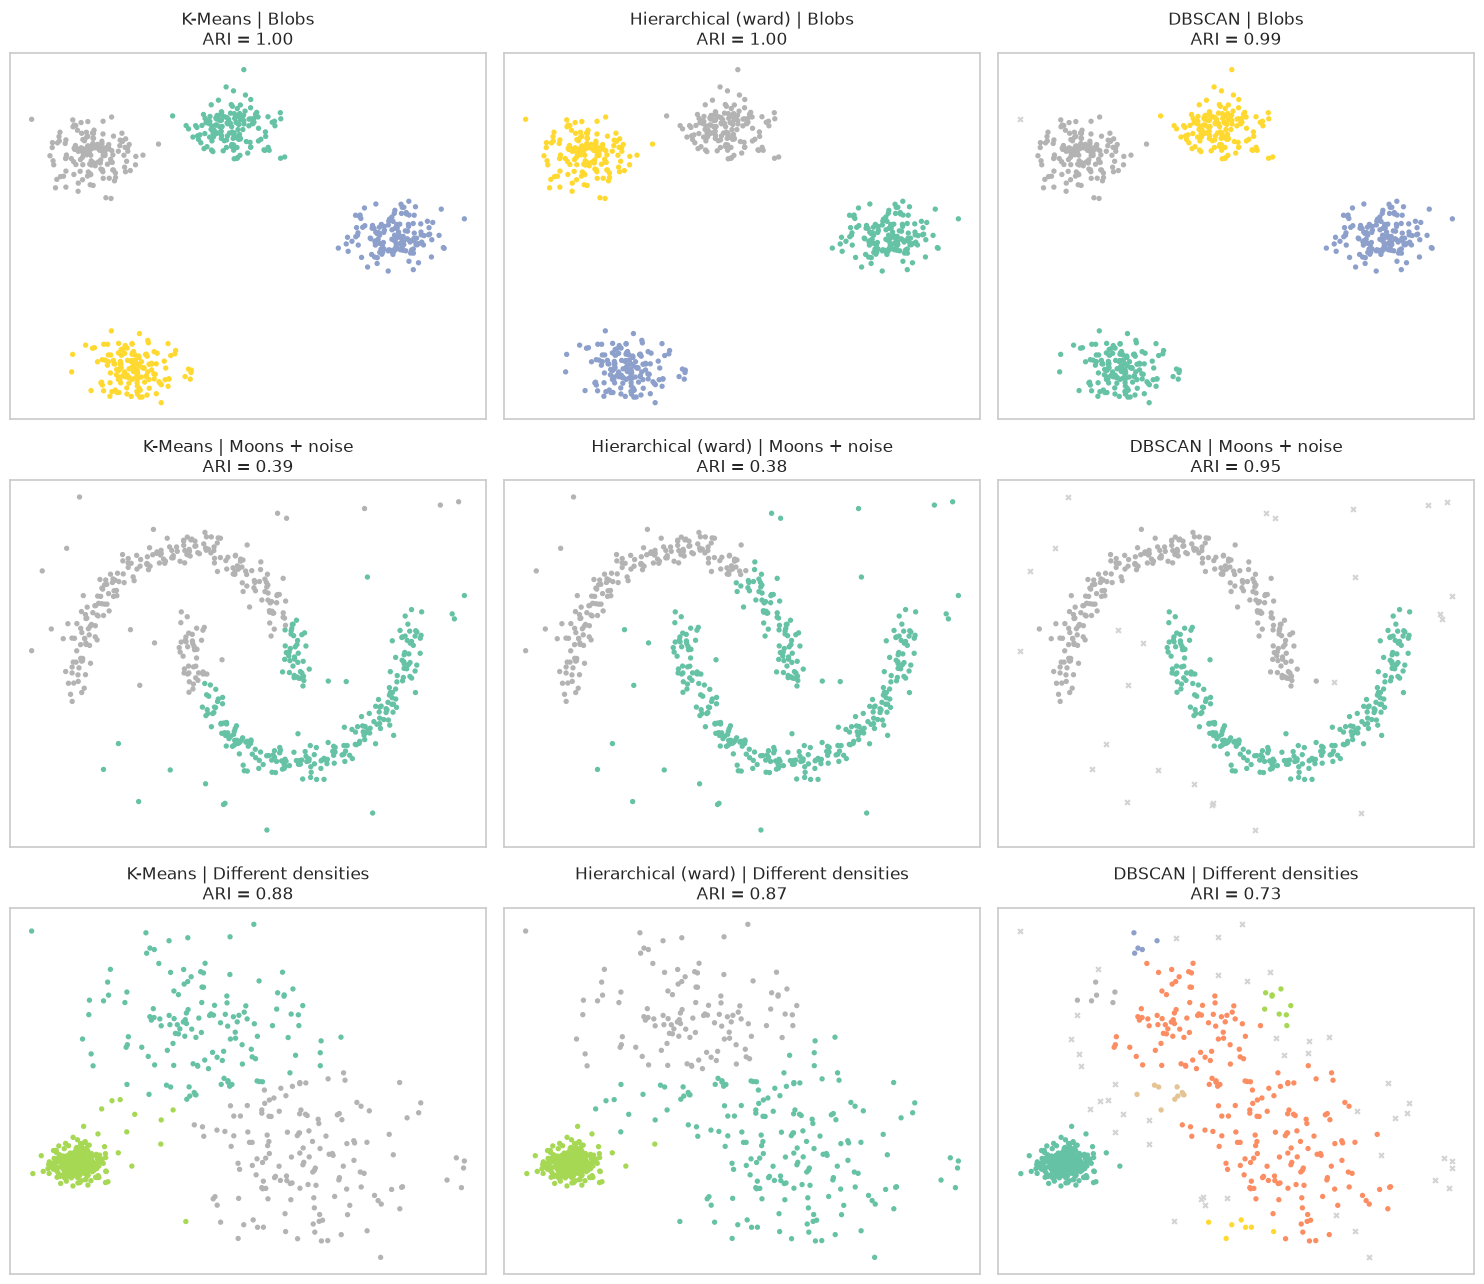

In [18]:
# Third toy dataset: one tight and two spread-out groups
X_dens, y_dens = make_blobs(n_samples=[300, 150, 150], centers=[[0, 0], [5, 0], [2.5, 4]],
                            cluster_std=[0.3, 1.4, 1.4], random_state=RANDOM_STATE)

toy_sets = {
    "Blobs": (StandardScaler().fit_transform(X_blobs), y_blobs, 4),
    "Moons + noise": (StandardScaler().fit_transform(X_moons), y_moons, 2),
    "Different densities": (StandardScaler().fit_transform(X_dens), y_dens, 3),
}

algorithms = {
    "K-Means": lambda k: KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE),
    "Hierarchical (ward)": lambda k: AgglomerativeClustering(n_clusters=k, linkage="ward"),
    "DBSCAN": lambda k: DBSCAN(eps=0.25, min_samples=5),   # k is ignored: DBSCAN finds it alone
}

fig, axes = plt.subplots(3, 3, figsize=(15, 13))
for row, (data_name, (X_toy, y_toy, k)) in enumerate(toy_sets.items()):
    for col, (algo_name, make_algo) in enumerate(algorithms.items()):
        labels = make_algo(k).fit_predict(X_toy)
        ax = axes[row, col]
        noise = labels == -1
        ax.scatter(X_toy[~noise, 0], X_toy[~noise, 1], c=labels[~noise], cmap="Set2", s=8)
        ax.scatter(X_toy[noise, 0], X_toy[noise, 1], c="lightgrey", marker="x", s=12)
        ax.set_title(f"{algo_name} | {data_name}\nARI = {adjusted_rand_score(y_toy, labels):.2f}")
        ax.set_xticks([])
        ax.set_yticks([])
plt.tight_layout()
save_fig("04_clustering_comparison")
plt.show()

What the grid shows:
- **Blobs:** all three do well. When clusters are round and separated, choose the simplest (K-Means).
- **Moons:** K-Means and ward cut the moons with a straight line, because they look for round groups around centres. DBSCAN follows the shape and isolates the noise.
- **Different densities:** now DBSCAN struggles: with one `eps` for everything, the tight group is fine but the spread-out groups get partly labelled as noise or merged. K-Means and ward handle this case better.

**There is no best algorithm, only a best algorithm for a given shape of data.**

### "Which clustering when?" cheat sheet

| | **K-Means** | **Hierarchical** | **DBSCAN** |
|---|---|---|---|
| Must choose k? | Yes | No: cut the tree afterwards | No: choose `eps` and `min_samples` instead |
| Cluster shapes | Round, similar size | Depends on linkage (ward ≈ round) | Any shape |
| Outliers / noise | Forced into clusters, pull centroids | Forced into clusters | Labelled as noise (−1) |
| Different densities | OK | OK | Struggles (try HDBSCAN) |
| Data size | Millions of rows | Up to ~10–20 thousand rows | Up to ~hundreds of thousands (low dimensions) |
| Explainability | Centroid = "average member" | **Dendrogram** = the whole story | Hard to summarise |
| Typical AEC use | Typical load profiles, segmenting building stock | Typologies, comparing cities or projects | **Point clouds**, GPS traces, detecting outliers in sensor data |

# 3. Dimensionality reduction

A dataset with 24 columns is a cloud of points in 24 dimensions. We cannot look at it, and as section 1.3 showed, distances in it can be misleading. **Dimensionality reduction** builds a few **new columns** that summarise the old ones.

Architects do this all the time: a **plan** and a **section** are 2D projections of a 3D building. A good projection keeps what matters; a bad one hides it (a section through a corridor tells you little about the rooms). Dimensionality reduction methods look for the most informative "drawings" of the data.

Two uses:
1. **Visualisation:** squeeze the data into 2D to look at it (all three methods).
2. **Compression / features:** replace many correlated columns with a few components before clustering or a supervised model (mostly PCA).

## 3.1 PCA: Principal Component Analysis

**Intuition:** find the **camera angle** that shows the data at its widest.
- **PC1** (first principal component) is the direction in which the data varies the most.
- **PC2** is the direction of most remaining variation, at a right angle to PC1. And so on.
- Each component is a **weighted mix of the original columns**; the weights are called **loadings**, and they tell you what the component *means*.
- **Explained variance ratio:** how much of the total variation each component captures. If the first 2 components explain 90%, a 2D plot shows almost everything.

Below: 300 flats described by floor area and number of rooms, two strongly related columns. PCA finds the "size" direction (PC1) and a small leftover direction (PC2).

Explained variance ratio: [0.951 0.049]
PC1 loadings (area, rooms): [0.71 0.71]
Figure saved to figures/05_pca_intuition.png


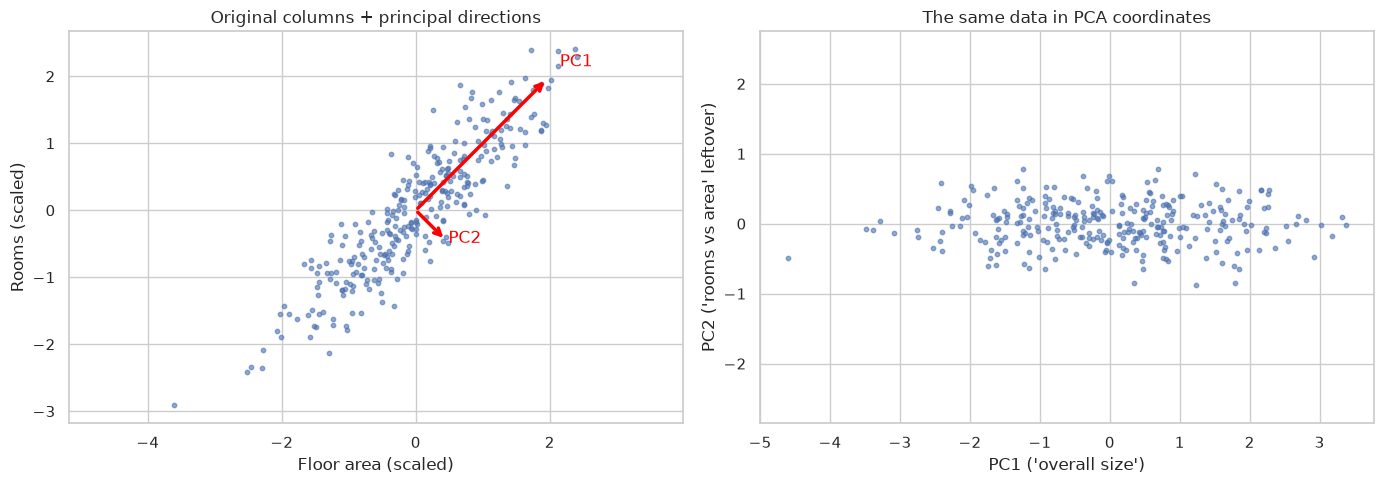

In [19]:
from sklearn.decomposition import PCA

# Two related columns: bigger flats have more rooms
area = rng.normal(90, 30, 300)
rooms = area / 25 + rng.normal(0, 0.6, 300)
flats_toy = StandardScaler().fit_transform(np.column_stack([area, rooms]))

pca_toy = PCA(n_components=2).fit(flats_toy)
print("Explained variance ratio:", pca_toy.explained_variance_ratio_.round(3))
print("PC1 loadings (area, rooms):", pca_toy.components_[0].round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(flats_toy[:, 0], flats_toy[:, 1], s=10, alpha=0.6)
for length, vector, name in zip(pca_toy.explained_variance_, pca_toy.components_, ["PC1", "PC2"]):
    arrow = vector * 2 * np.sqrt(length)
    axes[0].annotate("", xy=arrow, xytext=(0, 0), arrowprops=dict(arrowstyle="->", lw=2.5, color="red"))
    axes[0].text(*arrow * 1.1, name, color="red", fontsize=12)
axes[0].set_xlabel("Floor area (scaled)")
axes[0].set_ylabel("Rooms (scaled)")
axes[0].set_title("Original columns + principal directions")
axes[0].axis("equal")

flats_pca = pca_toy.transform(flats_toy)
axes[1].scatter(flats_pca[:, 0], flats_pca[:, 1], s=10, alpha=0.6)
axes[1].set_xlabel("PC1 ('overall size')")
axes[1].set_ylabel("PC2 ('rooms vs area' leftover)")
axes[1].set_title("The same data in PCA coordinates")
axes[1].axis("equal")
plt.tight_layout()
save_fig("05_pca_intuition")
plt.show()

PC1 alone carries almost all the information, with roughly equal loadings for area and rooms: it is an **"overall size"** axis. PC2 is what's left: flats with more or fewer rooms than usual for their area. We could drop PC2 and describe each flat with **one number instead of two**, losing very little.

| | |
|---|---|
| **Key parameter** | `n_components`: a number (e.g. 2) or a share of variance to keep (e.g. `0.95`) |
| **Strengths** | Fast, deterministic, **interpretable** (loadings), can transform new data and even approximately go back (`inverse_transform`), works inside pipelines |
| **Weaknesses** | **Linear:** it can only rotate and squash, so curved structures get flattened; needs scaling |

## 3.2 t-SNE

**t-SNE** (*t-distributed Stochastic Neighbour Embedding*) is built only for **visualisation**. Instead of keeping the big directions, it tries to keep **neighbourhoods**: points that are neighbours in the high-dimensional space should stay neighbours in the 2D picture. It is excellent at revealing **groups**.

| | |
|---|---|
| **Key parameter** | `perplexity` (≈ how many neighbours each point "pays attention to", typically 5–50) |
| **Strengths** | Reveals clusters and local structure that PCA misses |
| **Weaknesses** | Slow on large data; random (different runs look different); **cannot transform new data**; the picture is easy to over-interpret |

⚠️ **Watch out:** in a t-SNE plot, **the size of a cluster and the distance between clusters mean (almost) nothing**. t-SNE expands dense groups and shrinks sparse ones. Look at **which points are together**, not at how big or how far apart the groups are. The demo below makes this concrete: a very tight group and a very spread-out group come out the same size.

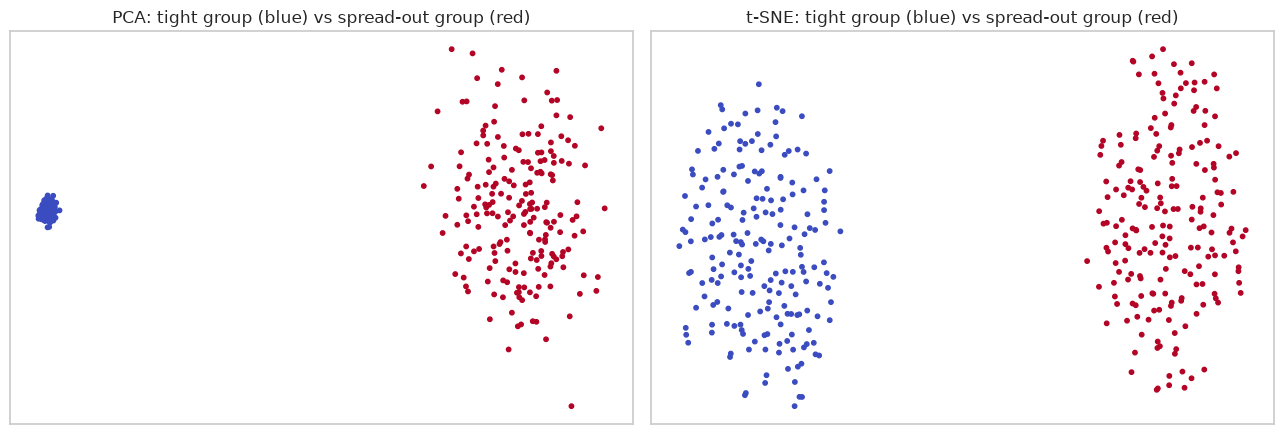

In [20]:
from sklearn.manifold import TSNE

# Two groups in 10 dimensions: one very tight (std 0.3), one very spread out (std 3)
X_sizes, y_sizes = make_blobs(n_samples=[200, 200], n_features=10, centers=[np.zeros(10), np.full(10, 12)],
                              cluster_std=[0.3, 3.0], random_state=RANDOM_STATE)

pca_view = PCA(n_components=2).fit_transform(X_sizes)
tsne_view = TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE).fit_transform(X_sizes)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, view, name in zip(axes, [pca_view, tsne_view], ["PCA", "t-SNE"]):
    ax.scatter(view[:, 0], view[:, 1], c=y_sizes, cmap="coolwarm", s=10)
    ax.set_title(f"{name}: tight group (blue) vs spread-out group (red)")
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

PCA keeps the real proportions: the blue group is a dot, the red one a large cloud. **t-SNE makes both groups look alike.** Both pictures are "correct"; they answer different questions.

## 3.3 UMAP

**UMAP** (*Uniform Manifold Approximation and Projection*) is a newer method with the same goal as t-SNE: keep neighbourhoods in a 2D picture. It is usually **faster**, tends to keep more of the **global** arrangement of the groups, and, unlike t-SNE, it **can transform new data** (`.transform`). It lives in the separate `umap-learn` package.

| Parameter | Effect |
|---|---|
| `n_neighbors` (default 15) | Small = focus on fine local detail; large = focus on the big picture |
| `min_dist` (default 0.1) | Small = tightly packed clusters; large = more spread-out picture |

The same warning as t-SNE applies: sizes and distances between clusters are only roughly meaningful.

💡 **Tip – see it for yourself:** [Understanding UMAP](https://pair-code.github.io/understanding-umap/) (Google PAIR) is an excellent interactive explainer. It shows step by step how UMAP builds its picture, compares it with t-SNE on the same datasets, and lets you move `n_neighbors`, `min_dist` and t-SNE's `perplexity` to watch the result change. Spend ten minutes playing with it: it makes the warnings above very concrete.

## 3.4 PCA vs t-SNE vs UMAP on a curved surface

A classic test: an **S-shaped surface** in 3D (think of a curved roof shell or a ramp), coloured by the position along the surface. A good 2D method should **unroll** the S into a flat strip, with the colours in order.

The first UMAP call takes a few extra seconds: the library compiles itself the first time.

Figure saved to figures/06_pca_tsne_umap_s_curve.png


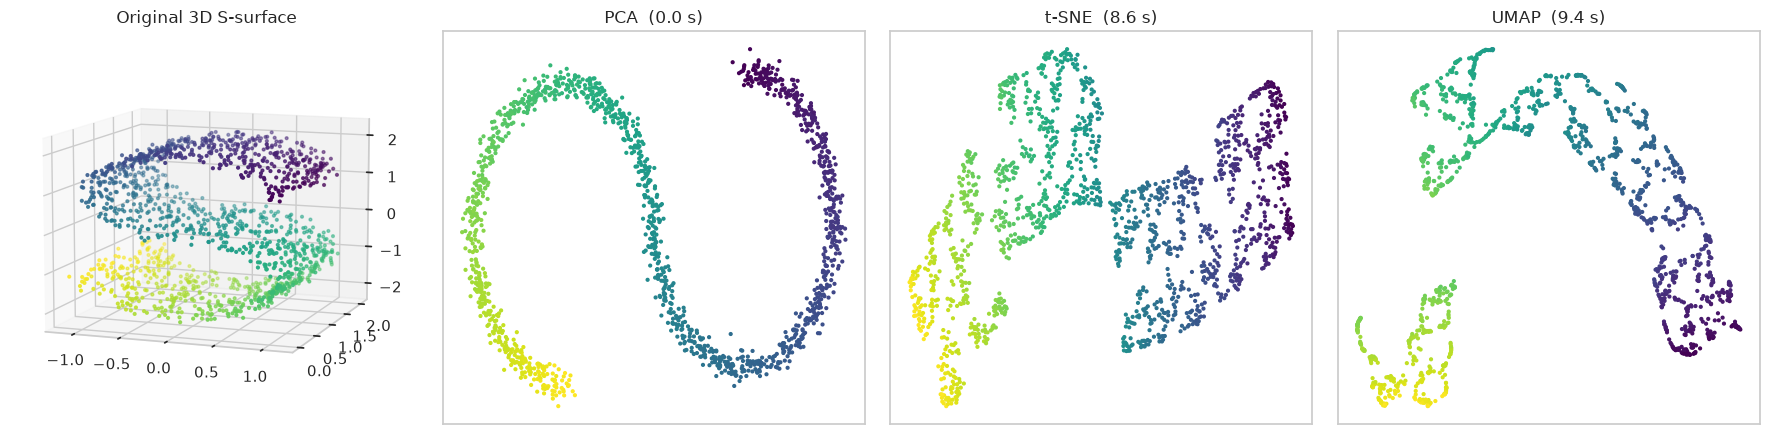

In [21]:
import umap
from sklearn.datasets import make_s_curve

X_s, position = make_s_curve(n_samples=1500, noise=0.05, random_state=RANDOM_STATE)

reducers = {
    "PCA": PCA(n_components=2),
    "t-SNE": TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE),
    "UMAP": umap.UMAP(n_components=2, n_neighbors=15, random_state=RANDOM_STATE, n_jobs=1),
}

fig = plt.figure(figsize=(18, 4.5))
ax = fig.add_subplot(1, 4, 1, projection="3d")
ax.scatter(X_s[:, 0], X_s[:, 1], X_s[:, 2], c=position, cmap="viridis", s=4)
ax.set_title("Original 3D S-surface")
ax.view_init(elev=10, azim=-70)

for i, (name, reducer) in enumerate(reducers.items(), start=2):
    start = time.time()
    view = reducer.fit_transform(X_s)
    ax = fig.add_subplot(1, 4, i)
    ax.scatter(view[:, 0], view[:, 1], c=position, cmap="viridis", s=4)
    ax.set_title(f"{name}  ({time.time() - start:.1f} s)")
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
save_fig("06_pca_tsne_umap_s_curve")
plt.show()

- **PCA** looks at the S from the side: a linear projection cannot unroll a curve, so the ends of the S overlap in colour order.
- **t-SNE** and **UMAP** follow the surface and lay it out flat, with the colours in order (t-SNE can tear or fold it a bit).

### Dimensionality reduction cheat sheet

| | **PCA** | **t-SNE** | **UMAP** |
|---|---|---|---|
| Type | Linear (rotation) | Non-linear | Non-linear |
| Keeps | Global variance (big directions) | Local neighbourhoods | Local + some global structure |
| Speed | Very fast | Slow on large data | Fast |
| New data (`.transform`)? | Yes | **No** | Yes |
| Same result every run? | Yes | No (fix `random_state`) | No (fix `random_state`) |
| Interpretable axes? | **Yes** (loadings) | No | No |
| Use for | Understanding, compression, features for models, first look | Pictures of clusters | Pictures of clusters, sometimes features |

💡 **Tip:** a very common workflow is **scale → PCA (keep ~95% of the variance) → cluster → draw the result with t-SNE or UMAP**. PCA removes noise and redundancy, the clustering runs on clean features, and the non-linear map makes a readable picture.

# 4. Application A – Building typologies (energy efficiency dataset)

We reuse the **Energy Efficiency** dataset from Day 2 (Tsanas & Xifara, 2012): 768 buildings simulated in Ecotect, described by 8 design parameters, with their heating and cooling loads.

On Day 2 the loads were the **target**. Today we **hide them**: we cluster only the 8 design parameters, and use the loads **afterwards** to check whether the groups we found differ in performance. This is a common trick: **interpret clusters with variables that were not used to build them.**

| Column | Meaning |
|---|---|
| `relative_compactness` | Volume vs envelope (1 = very compact) |
| `surface_area`, `wall_area`, `roof_area` | Envelope areas (m²) |
| `overall_height` | 3.5 m (1 storey) or 7 m (2 storeys) |
| `orientation` | 2 = N, 3 = E, 4 = S, 5 = W |
| `glazing_area` | Windows as a share of floor area: 0, 10, 25, 40% |
| `glazing_distribution` | 0 = none, 1 = uniform, 2–5 = mostly N / E / S / W |

In [22]:
energy = kh.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    "elikplim/eergy-efficiency-dataset",
    "ENB2012_data.csv",
)
energy = energy.rename(columns={
    "X1": "relative_compactness", "X2": "surface_area", "X3": "wall_area", "X4": "roof_area",
    "X5": "overall_height", "X6": "orientation", "X7": "glazing_area", "X8": "glazing_distribution",
    "Y1": "heating_load", "Y2": "cooling_load",
})

design_cols = ["relative_compactness", "surface_area", "wall_area", "roof_area",
               "overall_height", "orientation", "glazing_area", "glazing_distribution"]
load_cols = ["heating_load", "cooling_load"]   # hidden until we interpret the clusters

print(f"{energy.shape[0]} buildings, {len(design_cols)} design parameters")
energy[design_cols].nunique().to_frame("distinct values")

768 buildings, 8 design parameters


,distinct values
relative_compactness,12
surface_area,12
wall_area,7
roof_area,4
overall_height,2
orientation,4
glazing_area,4
glazing_distribution,6


Every column has only a handful of distinct values. This is not a sample of real buildings, it is a **parametric design grid**: 12 building shapes × 4 orientations × 16 glazing options = 768. Keep that in mind; it will explain what we find.

## 4.1 PCA: how many "real" dimensions?

Figure saved to figures/07_energy_pca.png


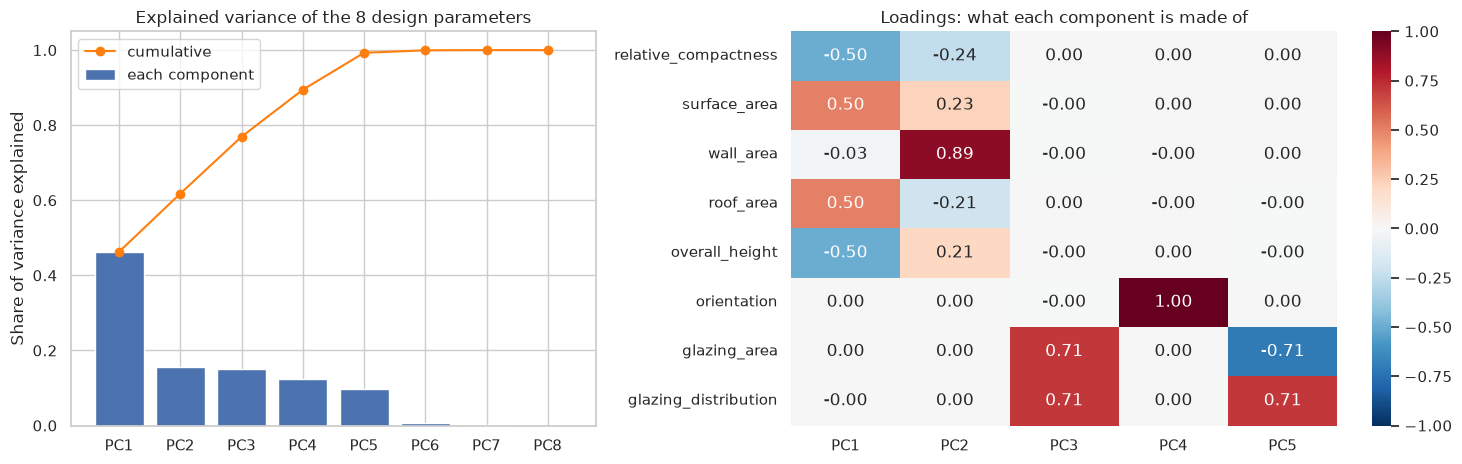

Cumulative variance: {'PC1': np.float64(0.463), 'PC2': np.float64(0.618), 'PC3': np.float64(0.769), 'PC4': np.float64(0.894), 'PC5': np.float64(0.993), 'PC6': np.float64(0.999), 'PC7': np.float64(1.0), 'PC8': np.float64(1.0)}


In [23]:
X_design = StandardScaler().fit_transform(energy[design_cols])

pca_design = PCA().fit(X_design)
explained = pca_design.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 1.3]})
components = [f"PC{i + 1}" for i in range(len(explained))]
axes[0].bar(components, explained, label="each component")
axes[0].plot(components, explained.cumsum(), color="tab:orange", marker="o", label="cumulative")
axes[0].set_ylabel("Share of variance explained")
axes[0].set_title("Explained variance of the 8 design parameters")
axes[0].legend()

loadings = pd.DataFrame(pca_design.components_[:5].T, index=design_cols, columns=components[:5])
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Loadings: what each component is made of")
plt.tight_layout()
save_fig("07_energy_pca")
plt.show()

print("Cumulative variance:", dict(zip(components, explained.cumsum().round(3))))

How to read it:
- **PC1 (46%)** mixes compactness, surface area, roof area and height with almost equal weights: it is a **"building shape"** axis. Low, spread-out shapes on one side, compact two-storey shapes on the other. These columns move together because each of the 12 shapes fixes all of them at once (the same redundancy we saw on Day 2).
- **PC2 (15%)** is mostly **wall area**, the part of the geometry that PC1 does not explain. So PC1 and PC2 together describe the **shape**.
- **PC3 (15%)** is **glazing** (area and distribution together), **PC4 (12%)** is **orientation** alone, and **PC5 (10%)** separates glazing area from glazing distribution. These parameters were varied **independently** by the designers of the simulation, so PCA cannot compress them: each needs its own component.
- PC6–PC8 explain almost nothing: **8 columns really contain 5 dimensions of information.**

## 4.2 Clustering: what do we want "similar" to mean?

We run K-Means for k = 2…14 twice:
1. on **all 8** design parameters;
2. on the **5 geometric** parameters only (the building shape), ignoring orientation and glazing.

Figure saved to figures/08_energy_silhouette.png


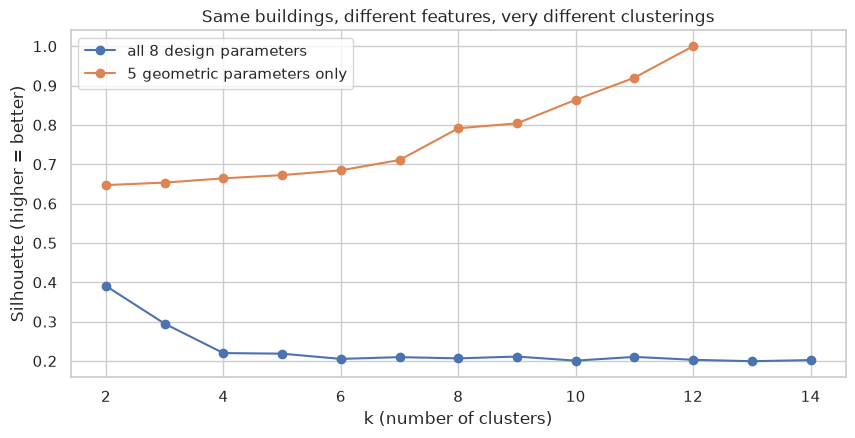

In [24]:
geometry_cols = ["relative_compactness", "surface_area", "wall_area", "roof_area", "overall_height"]
X_geometry = StandardScaler().fit_transform(energy[geometry_cols])

scan_all = scan_k(X_design, range(2, 15))
# Geometry has only 12 distinct combinations, so more than 12 clusters is impossible
scan_geometry = scan_k(X_geometry, range(2, 13))

plt.figure(figsize=(10, 4.5))
plt.plot(scan_all.index, scan_all["silhouette"], marker="o", label="all 8 design parameters")
plt.plot(scan_geometry.index, scan_geometry["silhouette"], marker="o", label="5 geometric parameters only")
plt.xlabel("k (number of clusters)")
plt.ylabel("Silhouette (higher = better)")
plt.title("Same buildings, different features, very different clusterings")
plt.legend()
save_fig("08_energy_silhouette")
plt.show()

In [25]:
# The 12 shapes are known from the simulation: we use them only to CHECK the clusters
shape_id = energy.groupby(["relative_compactness", "surface_area"]).ngroup()

for name, X_used in [("all 8 parameters", X_design), ("geometry only", X_geometry)]:
    labels = KMeans(n_clusters=12, n_init=10, random_state=RANDOM_STATE).fit_predict(X_used)
    print(f"k = 12 on {name:<17}: silhouette = {silhouette_score(X_used, labels):.2f}, "
          f"ARI vs the 12 shapes = {adjusted_rand_score(shape_id, labels):.2f}")

k = 12 on all 8 parameters : silhouette = 0.20, ARI vs the 12 shapes = 0.30
k = 12 on geometry only    : silhouette = 1.00, ARI vs the 12 shapes = 1.00


A striking result:
- With **all 8 parameters** the silhouette stays low for every k, and the clusters do not match the shapes. The algorithm is torn between geometry, orientation and glazing, which vary independently, so there are no clean groups to find.
- With **geometry only**, the silhouette climbs to **1.0 at k = 12**, and the clusters match the 12 building shapes **perfectly** (ARI = 1). K-Means has rediscovered the 12 shapes of the simulation without ever being told about them.

🤔 **Think about it:** neither result is "wrong". The question decides the features: *"which buildings have the same form?"* → geometry only; *"which buildings are similar in every design choice?"* → all parameters (and the answer is "the data has no natural groups, it's a grid"). **Choosing the features is choosing the definition of similarity**, and that is a design decision, not a technical one.

⚠️ **Watch out:** a perfect silhouette is a warning sign as much as good news. Here it happens because the data is a **simulated grid** with exactly 12 shapes repeated 64 times. Real building stocks are never this clean.

The ARI is a single number. A **cross-tabulation** shows *how* the clusters relate to the shapes: one row per building shape, one column per cluster, and in each cell the number of buildings. Each shape has 64 buildings (4 orientations × 16 glazing options).

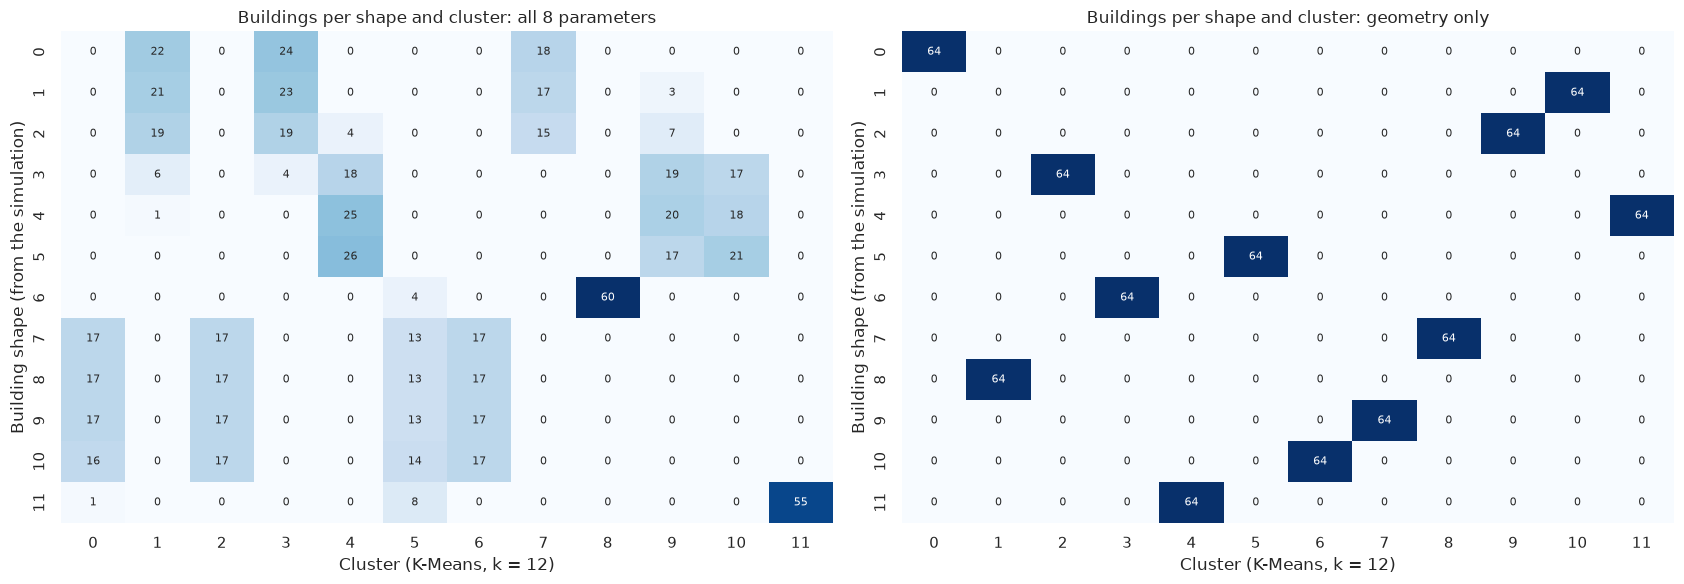

In [26]:
labels_all = KMeans(n_clusters=12, n_init=10, random_state=RANDOM_STATE).fit_predict(X_design)
labels_geometry = KMeans(n_clusters=12, n_init=10, random_state=RANDOM_STATE).fit_predict(X_geometry)

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for ax, labels, title in [(axes[0], labels_all, "all 8 parameters"), (axes[1], labels_geometry, "geometry only")]:
    table = pd.crosstab(shape_id, labels)
    sns.heatmap(table, annot=True, fmt="d", cmap="Blues", cbar=False, annot_kws={"size": 8}, ax=ax)
    ax.set_title(f"Buildings per shape and cluster: {title}")
    ax.set_xlabel("Cluster (K-Means, k = 12)")
    ax.set_ylabel("Building shape (from the simulation)")
plt.tight_layout()
plt.show()

The two heatmaps tell very different stories:
- **Geometry only (right):** every row has a single cell with **64**: each shape fills exactly one cluster, and each cluster holds exactly one shape. The cluster numbers are in a different order than the shape numbers (cluster numbers are arbitrary), which is why we compare with the ARI and not with an exact match.
- **All 8 parameters (left):** K-Means first groups **similar shapes into blocks** (shapes 0–2, shapes 3–5, shapes 7–10), then **splits each block by glazing and orientation** instead of by shape. Look at shapes 7–10: their buildings are spread almost evenly over the same four clusters (about 17, 17, 13 and 17 buildings each). Only two shapes keep most of their buildings in a cluster of their own: shape 6 (the largest wall area) and shape 11 (the most compact).
- **One thing never happens:** no cluster mixes one-storey shapes (0–5) with two-storey shapes (6–11). Height is the strongest difference in the data, as the dendrogram below will confirm.

💡 **Tip:** a cross-tab is the most direct way to compare clusters with **any** categorical variable you did not cluster on: building type, district, construction period, energy rating. Use `pd.crosstab(...)` with `normalize="index"` or `"columns"` to read shares instead of counts, as we do with the months in Application B.

## 4.3 A family tree of building shapes

The 12 shapes are few enough to draw a dendrogram of the shapes themselves. Each leaf is labelled with its compactness and height.

Figure saved to figures/09_energy_dendrogram.png


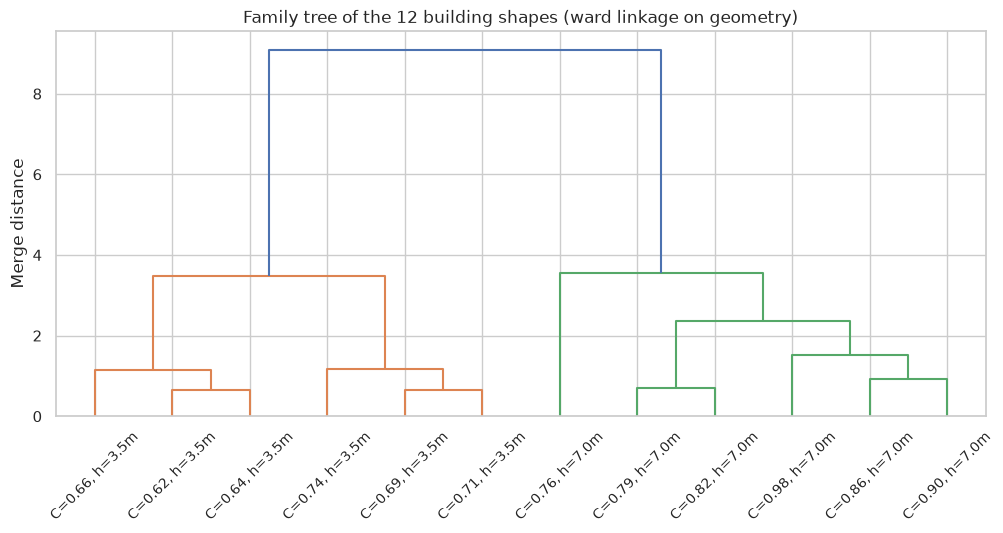

In [27]:
shapes = energy.groupby(geometry_cols, as_index=False).size()
shapes["label"] = [f"C={c:.2f}, h={h:.1f}m" for c, h in zip(shapes["relative_compactness"], shapes["overall_height"])]

shape_tree = linkage(StandardScaler().fit_transform(shapes[geometry_cols]), method="ward")

plt.figure(figsize=(12, 5))
dendrogram(shape_tree, labels=shapes["label"].tolist(), leaf_rotation=45, leaf_font_size=10, color_threshold=4)
plt.title("Family tree of the 12 building shapes (ward linkage on geometry)")
plt.ylabel("Merge distance")
save_fig("09_energy_dendrogram")
plt.show()

The highest split separates **one-storey** (3.5 m) from **two-storey** (7 m) shapes: height is the strongest difference in form. Lower down, shapes with similar compactness merge first. We can cut this tree at **4 families** and see whether the families differ in energy, which we never used.

In [28]:
energy["family"] = AgglomerativeClustering(n_clusters=4, linkage="ward").fit_predict(X_geometry)

# Profile each family: average design parameters + the hidden loads
family_profile = energy.groupby("family")[geometry_cols + load_cols].mean()
family_profile["buildings"] = energy["family"].value_counts().sort_index()
family_profile = family_profile.sort_values("heating_load")
family_profile

,relative_compactness,surface_area,wall_area,roof_area,overall_height,heating_load,cooling_load,buildings
family,,,,,,,,
1,0.713,710.500,269.500,220.500,3.500,12.105,15.029,192
3,0.640,784.000,343.000,220.500,3.500,14.572,17.114,192
0,0.870,583.100,313.600,134.750,7.000,30.398,32.443,320
2,0.760,661.500,416.500,122.500,7.000,35.664,36.407,64


Figure saved to figures/10_energy_families.png


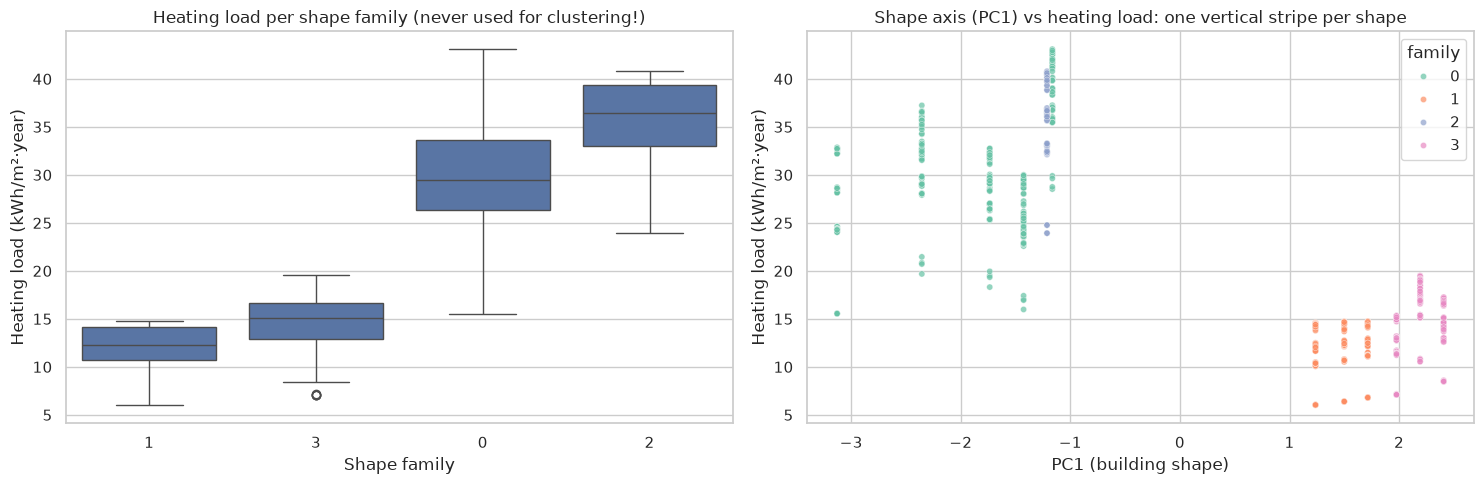

In [29]:
order = family_profile.index.tolist()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=energy, x="family", y="heating_load", order=order, ax=axes[0])
axes[0].set_title("Heating load per shape family (never used for clustering!)")
axes[0].set_xlabel("Shape family")
axes[0].set_ylabel("Heating load (kWh/m²·year)")

# PC1 and PC2 only contain geometry, so the 768 buildings would sit on 12 dots (64 on top of each other).
# Instead we plot the shape axis (PC1) against the hidden heating load.
shape_axis = PCA(n_components=1).fit_transform(X_design)[:, 0]
sns.scatterplot(x=shape_axis, y=energy["heating_load"], hue=energy["family"], palette="Set2", s=20, alpha=0.7, ax=axes[1])
axes[1].set_title("Shape axis (PC1) vs heating load: one vertical stripe per shape")
axes[1].set_xlabel("PC1 (building shape)")
axes[1].set_ylabel("Heating load (kWh/m²·year)")
axes[1].legend(title="family")
plt.tight_layout()
save_fig("10_energy_families")
plt.show()

The families, built **only from geometry**, have clearly different heating demands: the compact two-storey shapes need much more heating per m² than the low, spread-out one-storey shapes in this simulation (the same pattern Day 2's models found through `overall_height` and `relative_compactness`). Within each family the spread comes from orientation and glazing.

On the right, every vertical stripe is a shape: 64 buildings with identical geometry (two shapes happen to share the same PC1 value, around −1.2, so their stripes overlap). The **spread inside a stripe** (often 10–20 kWh/m²) comes from glazing and orientation; the **jump between stripes** comes from the shape. The shape decides the order of magnitude, and the glazing fine-tunes it.

🤔 **Think about it:** if you had to tell a client which early design decision matters most for heating, what would you say after seeing this plot?

# 5. Application B – Energy consumption profiles

Utilities and building managers want to know the **typical days** of a building: when the peaks happen, how weekends differ, what a holiday looks like. These **load profiles** guide tariff design, battery sizing, demand response and HVAC scheduling. Clustering daily curves is the standard way to find them.

| | |
|---|---|
| **Source** | UCI ML Repository, *Individual household electric power consumption*; Kaggle [uciml/electric-power-consumption-data-set](https://www.kaggle.com/datasets/uciml/electric-power-consumption-data-set) |
| **Origin** | **Measured** (not simulated): one house in Sceaux, near Paris |
| **Period** | December 2006 – November 2010 |
| **Resolution** | One reading per minute, about 2 million rows |
| **Main column** | `Global_active_power`: the electric power used by the whole house, in kilowatts (kW) |
| **Missing values** | Written as `?` in the file (about 1.25% of the minutes) |

We turn the minute data into a table with **one row per day** and **24 columns** (the average power in each hour). Each day becomes a **24-dimensional point**, a perfect playground for clustering and dimensionality reduction.

The raw file is 130 MB, so we process it once and save the small daily table in `data/`. The next runs read the small file.

In [30]:
profiles_path = DATA_DIR / "daily_load_profiles.csv"

if profiles_path.exists():
    daily = pd.read_csv(profiles_path, index_col="date", parse_dates=["date"])
    print(f"Loaded the saved daily profiles from {profiles_path}")
else:
    start = time.time()
    folder = Path(kh.dataset_download("uciml/electric-power-consumption-data-set"))
    raw = pd.read_csv(folder / "household_power_consumption.txt", sep=";", na_values="?",
                      usecols=["Date", "Time", "Global_active_power"], low_memory=False)
    raw["timestamp"] = pd.to_datetime(raw["Date"] + " " + raw["Time"], format="%d/%m/%Y %H:%M:%S")
    power = raw.set_index("timestamp")["Global_active_power"]

    # Minute data -> hourly averages. An hour with fewer than 45 valid minutes counts as missing
    hourly = power.resample("h").mean()
    hourly[power.resample("h").count() < 45] = np.nan

    # One row per day, one column per hour (0..23)
    table = pd.DataFrame({"date": hourly.index.normalize(), "hour": hourly.index.hour, "kw": hourly.values})
    daily = table.pivot_table(index="date", columns="hour", values="kw", aggfunc="mean", dropna=False)
    daily.columns = [f"h{h:02d}" for h in daily.columns]
    daily = daily.dropna()          # keep only complete days
    daily.to_csv(profiles_path)
    print(f"Processed {len(raw):,} minutes in {time.time() - start:.0f} s and saved {profiles_path}")

hour_cols = daily.columns.tolist()
print(f"{len(daily):,} complete days x {len(hour_cols)} hours")
daily.head(3)

Loaded the saved daily profiles from data/daily_load_profiles.csv
1,411 complete days x 24 hours


,h00,h01,h02,h03,h04,h05,h06,h07,h08,h09,h10,h11,h12,h13,h14,h15,h16,h17,h18,h19,h20,h21,h22,h23
date,,,,,,,,,,,,,,,,,,,,,,,,
2006-12-17,1.882,3.349,1.587,1.662,2.216,1.997,1.303,1.620,1.891,2.549,3.629,2.471,1.916,1.661,2.093,2.985,3.326,3.407,3.697,2.908,3.361,3.041,1.518,0.438
2006-12-18,0.276,0.313,0.284,0.310,1.026,0.293,0.610,2.450,2.082,1.629,1.310,1.562,1.756,1.682,1.733,1.784,1.949,2.155,2.403,2.615,3.051,2.170,1.739,1.547
2006-12-19,0.837,0.353,0.327,0.308,0.328,0.307,0.796,1.786,3.879,1.618,0.437,2.322,0.431,0.300,0.302,0.421,1.372,2.111,2.205,1.842,2.941,1.443,0.720,0.384


Figure saved to figures/11_load_raw_days.png


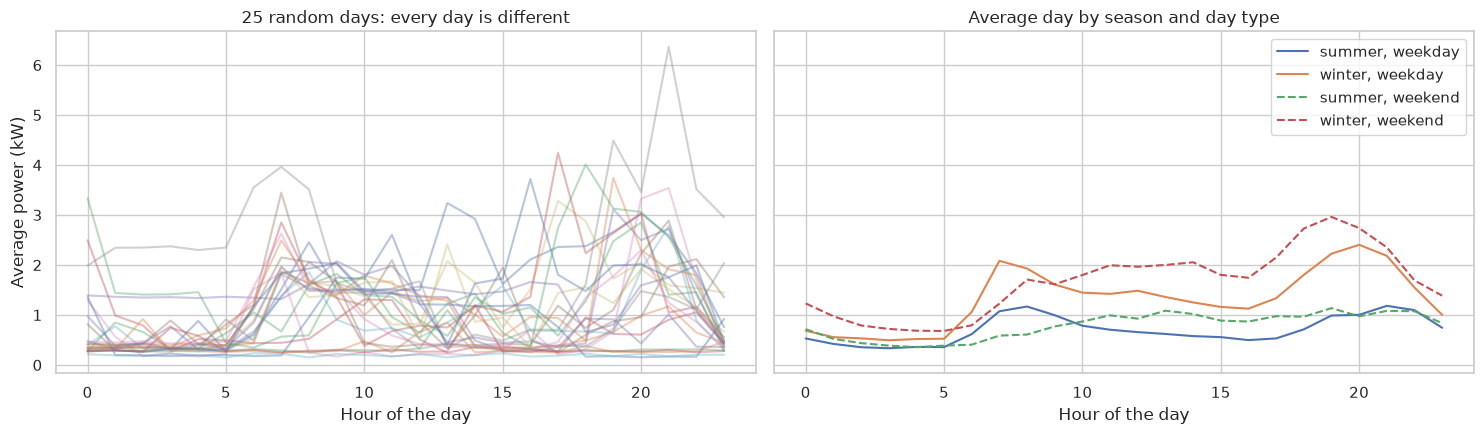

In [31]:
# Calendar information: NOT used for clustering, only to interpret the clusters afterwards
calendar = pd.DataFrame(index=daily.index)
calendar["weekend"] = daily.index.dayofweek >= 5
calendar["month"] = daily.index.month
calendar["season"] = calendar["month"].map({12: "winter", 1: "winter", 2: "winter",
                                            3: "spring", 4: "spring", 5: "spring",
                                            6: "summer", 7: "summer", 8: "summer",
                                            9: "autumn", 10: "autumn", 11: "autumn"})

hours = np.arange(24)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for _, day in daily.sample(25, random_state=RANDOM_STATE).iterrows():
    axes[0].plot(hours, day.values, alpha=0.4)
axes[0].set_title("25 random days: every day is different")
axes[0].set_xlabel("Hour of the day")
axes[0].set_ylabel("Average power (kW)")

for (is_weekend, season), group in daily.groupby([calendar["weekend"], calendar["season"]]):
    if season in ["winter", "summer"]:
        axes[1].plot(hours, group.mean().values, linestyle="--" if is_weekend else "-",
                     label=f"{season}, {'weekend' if is_weekend else 'weekday'}")
axes[1].set_title("Average day by season and day type")
axes[1].set_xlabel("Hour of the day")
axes[1].legend()
plt.tight_layout()
save_fig("11_load_raw_days")
plt.show()

Individual days are noisy, but the averages already show a pattern: a morning peak, an evening peak, more use in winter, and weekends with a big **midday** peak. Can clustering find such patterns **without** being given the calendar?

## 5.1 Shape, not volume: normalising each day

Some days use more electricity overall (cold days, guests). If we cluster the raw kW, the clusters will mostly separate **high-use days from low-use days**. Often the more interesting question is **when** the electricity is used: the **shape** of the curve. So we divide each day by its own total: every row now sums to 1 and says *"what share of the day's electricity was used in each hour"*.

We keep the daily total as a separate column to describe the clusters later.

For the final model we will put this normalisation **inside a pipeline** (section 5.1, below), so the saved model can take a raw day in kW and normalise it by itself.

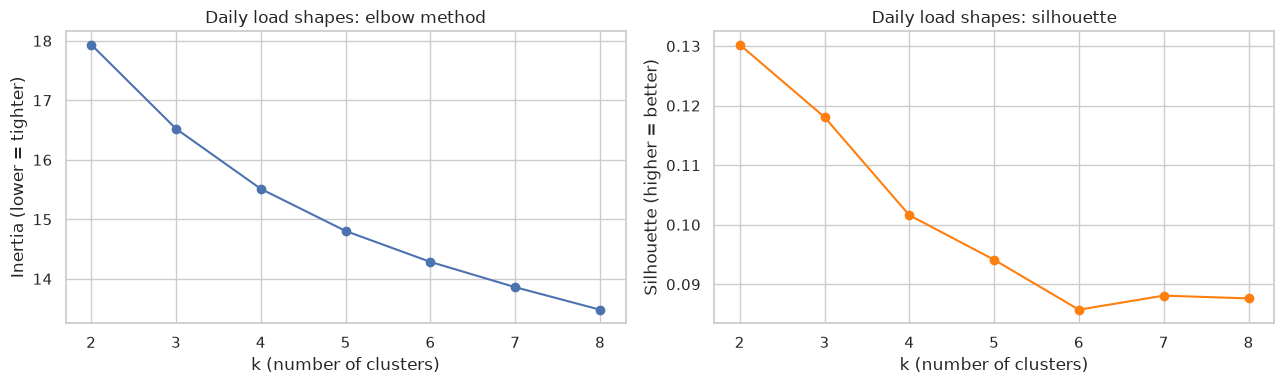

,inertia,silhouette
k,,
2,17.936,0.130
3,16.522,0.118
4,15.511,0.102
5,14.804,0.094
6,14.284,0.086
7,13.859,0.088
8,13.480,0.088


In [32]:
daily_total_kwh = daily.sum(axis=1)                     # 24 hourly averages in kW -> kWh per day
shapes_24h = daily.div(daily_total_kwh, axis=0)         # each row now sums to 1

load_scan = scan_k(shapes_24h, range(2, 9))
plot_k_scan(load_scan, "Daily load shapes")
plt.show()
load_scan

This is what **real data** looks like: no clear elbow and a **low silhouette** for every k (around 0.1). Daily habits form a **continuum**, not separate islands; there is always a day halfway between two "types".

That does not make clustering useless. It means the clusters are **useful summaries** rather than natural categories, so we choose k for **interpretability**: **k = 4** gives a handful of typical days that a building manager can work with. Let's look at them.

### The profile model as a pipeline

Before plotting the profiles, we build the model the way we would deliver it: as a **`Pipeline`**, like on Day 2.

- **`Normalizer(norm="l1")`** divides every row by the sum of its values: exactly our "share of the day" normalisation. Inside the pipeline, the model accepts **raw kW** and normalises each new day by itself, so nobody using the model can forget this step.
- **`KMeans(n_clusters=4)`** then groups the normalised days.

💡 **Tip:** no `StandardScaler` here. All 24 columns are shares of the same day, in the same unit, so scaling each hour separately would give rare night-time variations the same weight as the big evening peak.

Figure saved to figures/12_load_profiles.png


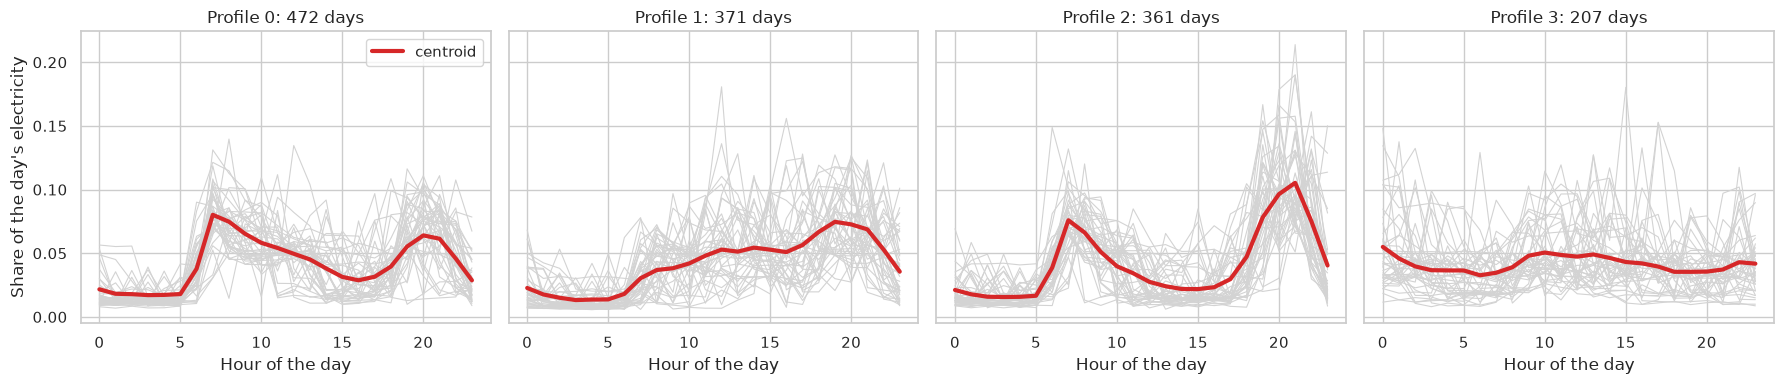

In [33]:
N_PROFILES = 4
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer

profile_model = make_pipeline(
    Normalizer(norm="l1"),                                               # each day / its total
    KMeans(n_clusters=N_PROFILES, n_init=10, random_state=RANDOM_STATE),
)
calendar["profile"] = profile_model.fit_predict(daily)                    # raw kW in, profile out
centroids = profile_model[-1].cluster_centers_                            # the last step is the K-Means model

fig, axes = plt.subplots(1, N_PROFILES, figsize=(18, 4), sharey=True)
for p, ax in enumerate(axes):
    members = shapes_24h[calendar["profile"] == p]
    for _, day in members.sample(min(40, len(members)), random_state=RANDOM_STATE).iterrows():
        ax.plot(hours, day.values, color="lightgrey", lw=0.8)
    ax.plot(hours, centroids[p], color="tab:red", lw=3, label="centroid")
    ax.set_title(f"Profile {p}: {len(members)} days")
    ax.set_xlabel("Hour of the day")
axes[0].set_ylabel("Share of the day's electricity")
axes[0].legend()
plt.tight_layout()
save_fig("12_load_profiles")
plt.show()

The red line is each cluster's **centroid**, the "average day" of the profile; the grey lines are 40 real days from it. Now the decisive step: **interpretation**, using information the algorithm never saw (the calendar and the daily total).

In [34]:
profile_summary = pd.DataFrame({
    "days": calendar["profile"].value_counts().sort_index(),
    "share_weekend": calendar.groupby("profile")["weekend"].mean(),
    "median_kwh_per_day": daily_total_kwh.groupby(calendar["profile"]).median(),
    "peak_hour": [int(np.argmax(c)) for c in centroids],
})
profile_summary

,days,share_weekend,median_kwh_per_day,peak_hour
profile,,,,
0,472,0.100,25.838,7
1,371,0.609,32.496,19
2,361,0.094,24.355,21
3,207,0.435,16.990,0


Figure saved to figures/13_load_profiles_by_month.png


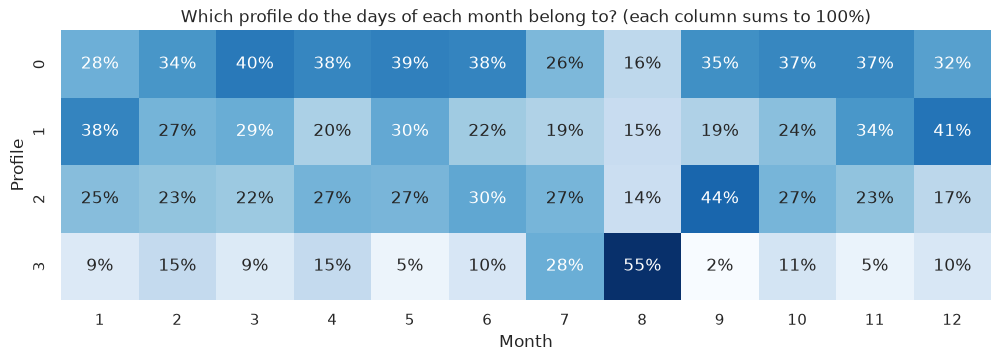

In [35]:
month_share = pd.crosstab(calendar["profile"], calendar["month"], normalize="columns")

plt.figure(figsize=(12, 3.5))
sns.heatmap(month_share, annot=True, fmt=".0%", cmap="Blues", cbar=False)
plt.title("Which profile do the days of each month belong to? (each column sums to 100%)")
plt.xlabel("Month")
plt.ylabel("Profile")
save_fig("13_load_profiles_by_month")
plt.show()

Now the profiles have names:

| Profile | Shape of the centroid | Calendar and volume (never used by K-Means) | A name |
|---|---|---|---|
| **0** | Sharp morning peak at 7:00, a second peak around 20:00, moderate use in between | 90% weekdays, ~26 kWh/day, all year round | **Workday, someone home in the morning** |
| **2** | Morning peak, almost nothing during the day, a **strong evening peak** at 21:00 | 91% weekdays, ~24 kWh/day | **Workday, house empty during the day** |
| **1** | Low at night, rising through the day, highest in the evening | **61% weekends**, the **highest** use (~32 kWh/day), most common in **winter** (Nov–Jan) | **At home all day** (weekends, winter days) |
| **3** | **Flat**: no peaks at all, the share at midnight is as high as at noon | Only ~17 kWh/day, **55% of all August days** and 28% of July | **Nobody home**: summer holidays, only the fridge and standby devices run |

None of these labels was given to the algorithm. K-Means only saw 24 numbers per day, and we recovered **workdays, weekends and the August holidays** from the shape of the curve alone. This is what interpretation means in unsupervised learning: the clusters become knowledge only when we connect them to the context.

💡 **Tip:** for a building manager, these centroids are directly usable: profile 2 (empty during the day) is the obvious candidate for lowering the heating setpoint between 9:00 and 17:00, and profile 3 tells you how much the house uses when nobody is there (its **base load**).

## 5.2 Are the profiles stable?

With a silhouette of 0.1 we should ask: are these four profiles a real pattern, or an accident of this particular run? Three checks:

1. **Another seed:** K-Means starts from random centroids. Does a different `random_state` give the same groups?
2. **Other data:** fit the pipeline on a random 80% of the days, assign all days, and compare. Do the groups survive losing some of the data?
3. **Another algorithm:** does hierarchical clustering (ward) cut the days the same way?

We compare each result with our profiles using the **adjusted Rand index** (1 = the same grouping, whatever the cluster numbers are; 0 = no better than random).

In [36]:
reference = calendar["profile"]

# 1. Same data, different seeds
seed_ari = [adjusted_rand_score(reference, make_pipeline(Normalizer(norm="l1"),
                                KMeans(n_clusters=N_PROFILES, n_init=10, random_state=seed)).fit_predict(daily))
            for seed in range(10)]

# 2. Fit on a random 80% of the days, then assign ALL days
subsample_rng = np.random.default_rng(RANDOM_STATE)
subsample_ari = []
for _ in range(10):
    rows = subsample_rng.choice(len(daily), size=int(0.8 * len(daily)), replace=False)
    model = make_pipeline(Normalizer(norm="l1"),
                          KMeans(n_clusters=N_PROFILES, n_init=10, random_state=RANDOM_STATE)).fit(daily.iloc[rows])
    subsample_ari.append(adjusted_rand_score(reference, model.predict(daily)))

# 3. A different algorithm on the same normalised days
ward_labels = AgglomerativeClustering(n_clusters=N_PROFILES, linkage="ward").fit_predict(shapes_24h)

stability = pd.DataFrame({
    "check": ["10 different seeds", "10 subsamples of 80%", "hierarchical (ward), k = 4"],
    "mean ARI": [np.mean(seed_ari), np.mean(subsample_ari), adjusted_rand_score(reference, ward_labels)],
    "min ARI": [np.min(seed_ari), np.min(subsample_ari), np.nan],
}).set_index("check")
stability

,mean ARI,min ARI
check,,
10 different seeds,0.978,0.959
10 subsamples of 80%,0.849,0.451
"hierarchical (ward), k = 4",0.345,NaN


How to read it:
- **Seeds (ARI ≈ 0.98):** K-Means finds practically the same four profiles from any starting point. The result is **reproducible**.
- **Subsamples (mean ARI ≈ 0.85):** most 80% subsamples give the same profiles, but one gives a clearly different split (minimum ≈ 0.45). The profiles are **fairly robust**, not unbreakable.
- **Ward (ARI ≈ 0.34):** a different algorithm cuts the days **quite differently**. With no gaps between groups (remember the silhouette), each algorithm places the borders of the continuum in its own way.

So the profiles are a **stable and useful summary for this method**, not natural categories that any method would find. That is exactly what a user of the model needs to know, and it goes into the **model card** (section 8).

## 5.3 Seeing 24 dimensions: PCA vs t-SNE vs UMAP

Each day is a point in 24 dimensions. Let's draw the 1,400 days in 2D with the three methods, coloured by the K-Means profile (top) and by whether the day is a weekend (bottom).

PCA: 0.0 s
t-SNE: 1.6 s
UMAP: 2.1 s
Figure saved to figures/14_load_pca_tsne_umap.png


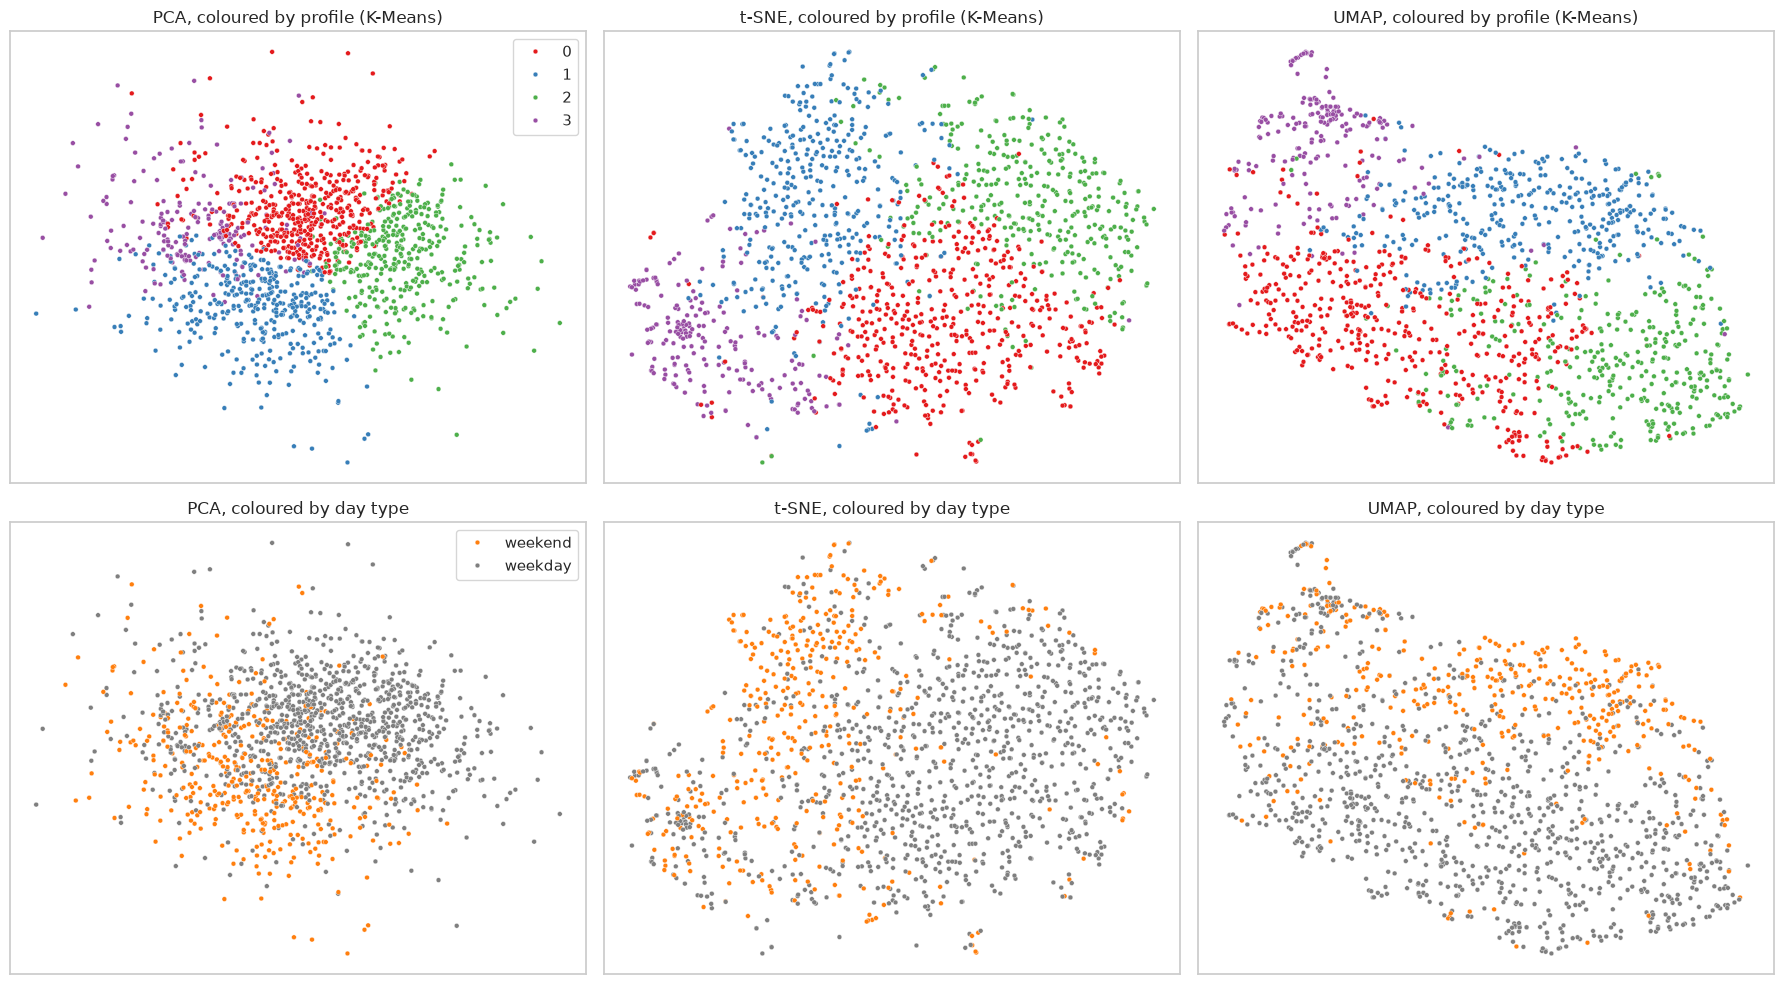

PCA: the first 2 components explain 36% of the variance, 14 components are needed for 90%


In [37]:
views = {}
for name, reducer in {
    "PCA": PCA(n_components=2),
    "t-SNE": TSNE(n_components=2, perplexity=30, random_state=RANDOM_STATE),
    "UMAP": umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=RANDOM_STATE, n_jobs=1),
}.items():
    start = time.time()
    views[name] = reducer.fit_transform(shapes_24h)
    print(f"{name}: {time.time() - start:.1f} s")

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for col, (name, view) in enumerate(views.items()):
    sns.scatterplot(x=view[:, 0], y=view[:, 1], hue=calendar["profile"].values, palette="Set1",
                    s=12, ax=axes[0, col], legend=(col == 0))
    axes[0, col].set_title(f"{name}, coloured by profile (K-Means)")
    sns.scatterplot(x=view[:, 0], y=view[:, 1], hue=np.where(calendar["weekend"], "weekend", "weekday"),
                    palette={"weekday": "tab:grey", "weekend": "tab:orange"}, s=12, ax=axes[1, col],
                    legend=(col == 0))
    axes[1, col].set_title(f"{name}, coloured by day type")
    for ax in axes[:, col]:
        ax.set_xticks([])
        ax.set_yticks([])
plt.tight_layout()
save_fig("14_load_pca_tsne_umap")
plt.show()

pca_profiles = PCA().fit(shapes_24h)
print(f"PCA: the first 2 components explain {pca_profiles.explained_variance_ratio_[:2].sum():.0%} of the variance, "
      f"{np.searchsorted(pca_profiles.explained_variance_ratio_.cumsum(), 0.9) + 1} components are needed for 90%")

What the three pictures tell us:
- **PCA** needs **14 of 24 components to keep 90%** of the variance, and the first two keep only about a third. Daily curves do not compress well in a straight-line way. In 2D the profiles appear as **neighbouring slices of one big cloud**, with no gaps between them: the same message as the low silhouette.
- **t-SNE** and **UMAP** pull apart what PCA overlaps. The **holiday profile (3)** becomes the most separated group, with a very tight knot of almost identical "empty house" days. **Weekend days** gather in one region (bottom row) even though the calendar was never used.
- The borders between profiles 0, 1 and 2 stay fuzzy in all three pictures. The clusters are a **useful way to cut a continuum**, not islands in the data.

⚠️ **Watch out:** don't read the distances between the groups in the t-SNE and UMAP plots, and don't trust the shapes of the groups. Re-run with another `random_state` or `perplexity` / `n_neighbors` and they will change; the **neighbourhoods** (which days sit together) are what stays.

# 6. Application C – Point cloud segmentation

**LiDAR** scanners (on drones, cars, tripods) and photogrammetry produce **point clouds**: millions of (x, y, z) points that sample the surfaces of a site. A raw point cloud is just points; to use it in a model (a BIM, a digital twin, a tree inventory) we need to know **which points belong to which object**. This is **segmentation**, and clustering is one of its basic tools.

To keep things fast and to know the right answer, we **generate** a small synthetic scan of a site:

| Object | How it is made |
|---|---|
| Ground | A flat 60 × 40 m plane, with a little measurement noise |
| Building A | A 15 × 15 m box, 12 m tall (points on walls and roof) |
| Building B | An **L-shaped** building, 25 m tall |
| 4 trees | A trunk and a round crown each, in a row |
| Noise | Random points in the air (birds, reflections, scanner errors) |

In a real project you would load a `.las` / `.ply` file (e.g. with the `laspy` or `open3d` libraries) instead of generating it.

In [38]:
def box_surface(x0, x1, y0, y1, height, density, rng):
    # Points on the 4 walls and the roof of a box (a LiDAR scanner sees surfaces, not volumes)
    faces = [  # (area, function that draws n points on the face)
        ((x1 - x0) * height, lambda n: np.column_stack([rng.uniform(x0, x1, n), np.full(n, y0), rng.uniform(0, height, n)])),
        ((x1 - x0) * height, lambda n: np.column_stack([rng.uniform(x0, x1, n), np.full(n, y1), rng.uniform(0, height, n)])),
        ((y1 - y0) * height, lambda n: np.column_stack([np.full(n, x0), rng.uniform(y0, y1, n), rng.uniform(0, height, n)])),
        ((y1 - y0) * height, lambda n: np.column_stack([np.full(n, x1), rng.uniform(y0, y1, n), rng.uniform(0, height, n)])),
        ((x1 - x0) * (y1 - y0), lambda n: np.column_stack([rng.uniform(x0, x1, n), rng.uniform(y0, y1, n), np.full(n, height)])),
    ]
    return np.vstack([draw(int(area * density)) for area, draw in faces])


def tree(x, y, rng, trunk_height=4, crown_radius=2.5, n_crown=350):
    # A vertical trunk and a spherical crown
    trunk = np.column_stack([x + rng.normal(0, 0.1, 40), y + rng.normal(0, 0.1, 40), rng.uniform(0, trunk_height, 40)])
    direction = rng.normal(size=(n_crown, 3))
    direction /= np.linalg.norm(direction, axis=1, keepdims=True)
    crown = np.array([x, y, trunk_height + crown_radius]) + direction * crown_radius
    return np.vstack([trunk, crown])


pc_rng = np.random.default_rng(RANDOM_STATE)
parts = {
    "ground": np.column_stack([pc_rng.uniform(0, 60, 6000), pc_rng.uniform(0, 40, 6000), pc_rng.normal(0, 0.05, 6000)]),
    "building A": box_surface(4, 19, 4, 19, 12, 2.5, pc_rng),
    "building B": np.vstack([box_surface(28, 52, 4, 12, 25, 1.5, pc_rng),      # the L is two boxes
                             box_surface(44, 52, 12, 24, 25, 1.5, pc_rng)]),
    "noise": np.column_stack([pc_rng.uniform(0, 60, 120), pc_rng.uniform(0, 40, 120), pc_rng.uniform(1, 30, 120)]),
}
for i, x in enumerate([10, 18, 26, 34]):
    parts[f"tree {i + 1}"] = tree(x, 32, pc_rng)

cloud = pd.DataFrame(np.vstack(list(parts.values())), columns=["x", "y", "z"])
cloud["true_object"] = np.concatenate([[name] * len(points) for name, points in parts.items()])
print(f"{len(cloud):,} points")
cloud["true_object"].value_counts()

14,374 points


true_object
ground        6000
building B    4332
building A    2362
tree 1         390
tree 2         390
tree 3         390
tree 4         390
noise          120
Name: count, dtype: int64

Figure saved to figures/15_point_cloud_truth.png


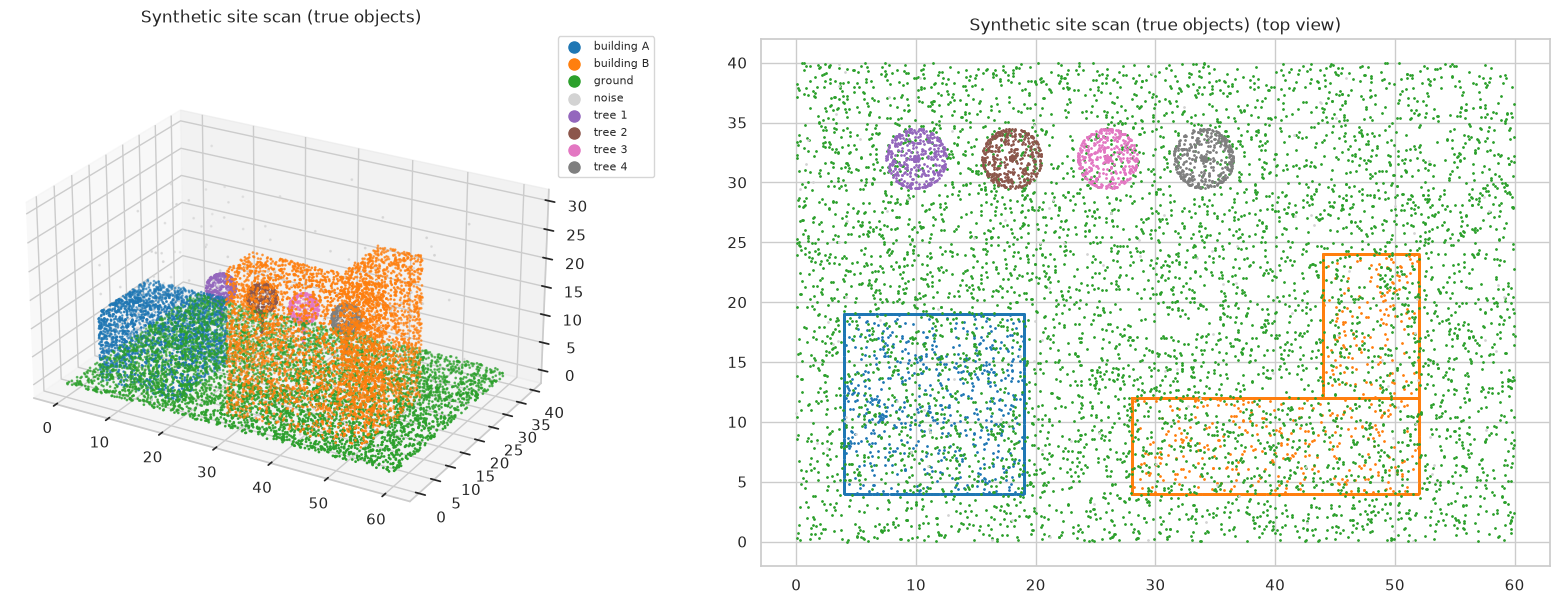

In [39]:
def plot_cloud(df, color_by, title, ax3d, ax_top, palette="tab10"):
    # A 3D view and a top view of a point cloud, coloured by a label column
    names = sorted(df[color_by].unique(), key=str)
    colors = dict(zip(names, sns.color_palette(palette, len(names))))
    for name in names:
        part = df[df[color_by] == name]
        color = "lightgrey" if name in ("noise", -1) else colors[name]
        ax3d.scatter(part["x"], part["y"], part["z"], s=1, color=color, label=str(name))
        ax_top.scatter(part["x"], part["y"], s=1, color=color)
    ax3d.set_title(title)
    ax3d.view_init(elev=25, azim=-60)
    ax3d.set_box_aspect((60, 40, 30))
    ax_top.set_title(f"{title} (top view)")
    ax_top.set_aspect("equal")
    ax3d.legend(markerscale=8, fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))


fig = plt.figure(figsize=(17, 6))
plot_cloud(cloud, "true_object", "Synthetic site scan (true objects)",
           fig.add_subplot(1, 2, 1, projection="3d"), fig.add_subplot(1, 2, 2))
plt.tight_layout()
save_fig("15_point_cloud_truth")
plt.show()

## 6.1 Step 1: remove the ground

The ground touches every object, so any distance-based method would glue everything together through it. The usual first step is to **remove the ground**. Our ground is flat, so a height threshold is enough; real terrain is not flat, and tools like **RANSAC plane fitting** or **cloth simulation filters** (in CloudCompare, PDAL, Open3D) do this job.

In [40]:
above_ground = cloud[cloud["z"] > 0.3].reset_index(drop=True)
print(f"Kept {len(above_ground):,} of {len(cloud):,} points after removing the ground")

Kept 8,267 of 14,374 points after removing the ground


## 6.2 Step 2: K-Means vs DBSCAN

We know there are **6 objects** (2 buildings, 4 trees), so K-Means even gets the right k, a luxury we would not have in a real scan. DBSCAN gets no k at all. Coordinates are already in the same unit (metres), so **no scaling** is needed here, and `eps` can be read directly as a distance in metres.

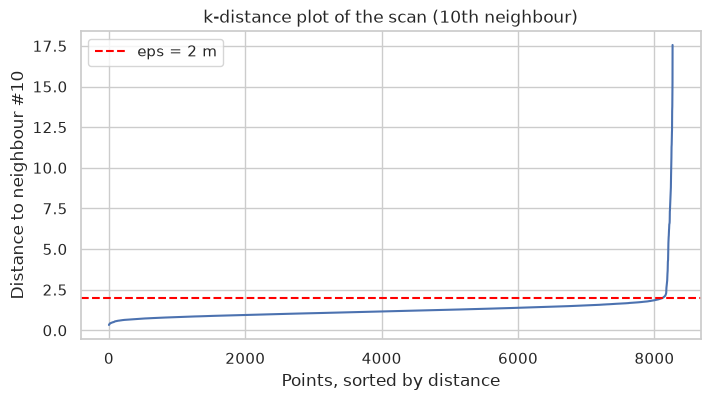

In [41]:
xyz = above_ground[["x", "y", "z"]].to_numpy()

k_distance_plot(xyz, 10, "k-distance plot of the scan (10th neighbour)")
plt.axhline(2.0, color="red", linestyle="--", label="eps = 2 m")
plt.legend()
plt.show()

Figure saved to figures/16_point_cloud_kmeans_vs_dbscan.png


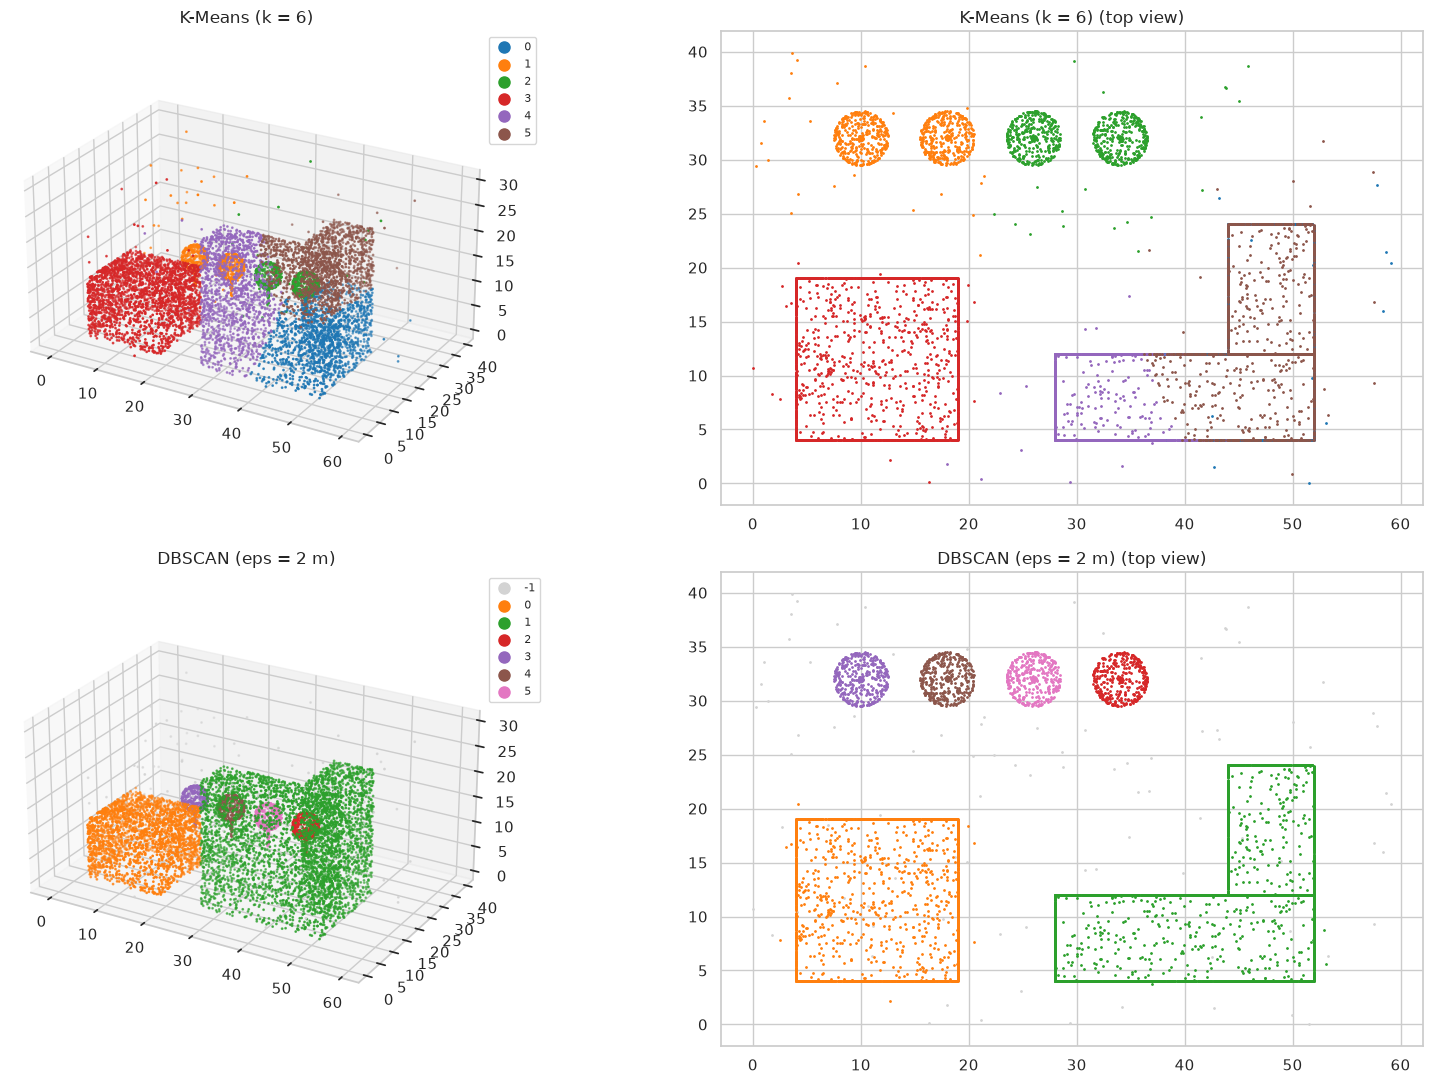

 kmeans: ARI vs true objects = 0.53
 dbscan: ARI vs true objects = 0.99
DBSCAN: 6 objects, 92 noise points


In [42]:
above_ground["kmeans"] = KMeans(n_clusters=6, n_init=10, random_state=RANDOM_STATE).fit_predict(xyz)
above_ground["dbscan"] = DBSCAN(eps=2.0, min_samples=10).fit_predict(xyz)

fig = plt.figure(figsize=(17, 11))
plot_cloud(above_ground, "kmeans", "K-Means (k = 6)",
           fig.add_subplot(2, 2, 1, projection="3d"), fig.add_subplot(2, 2, 2))
plot_cloud(above_ground, "dbscan", "DBSCAN (eps = 2 m)",
           fig.add_subplot(2, 2, 3, projection="3d"), fig.add_subplot(2, 2, 4))
plt.tight_layout()
save_fig("16_point_cloud_kmeans_vs_dbscan")
plt.show()

for method in ["kmeans", "dbscan"]:
    print(f"{method:>7}: ARI vs true objects = {adjusted_rand_score(above_ground['true_object'], above_ground[method]):.2f}")
print(f"DBSCAN: {above_ground['dbscan'].max() + 1} objects, {(above_ground['dbscan'] == -1).sum()} noise points")

The difference is dramatic:
- **K-Means (ARI ≈ 0.53)** cuts space into round regions around 6 centres. It **splits the L-shaped building B** into several pieces, **merges the trees in pairs**, and assigns every noise point to some object. Knowing the right k did not help: the objects are not round.
- **DBSCAN (ARI ≈ 0.99)** follows the surfaces wherever they go: it finds **exactly 6 objects** (2 buildings and 4 separate trees) and sets the floating points aside as noise (grey). Nobody told it how many objects there were.

That is why DBSCAN and its relatives are the standard tools for segmenting point clouds (Open3D has `cluster_dbscan` built in, and CloudCompare offers the same idea as "connected components").

⚠️ **Watch out:** `eps` must match the **point spacing** of your scan. With `eps = 1.5 m` (try it!) the sparser walls of building B fall apart into a dozen fragments, because some wall points no longer had 10 neighbours within 1.5 m. Denser scans need smaller `eps`; noisier ones need larger `min_samples`.

## 6.3 From points to objects

Once every point has an object label, we can measure each object: a first step from a scan to a **digital model**.

In [43]:
objects = (above_ground[above_ground["dbscan"] != -1]
           .groupby("dbscan")
           .agg(points=("x", "size"),
                x_min=("x", "min"), x_max=("x", "max"),
                y_min=("y", "min"), y_max=("y", "max"),
                height_m=("z", "max")))
objects["footprint_m"] = [f"{r.x_max - r.x_min:.0f} x {r.y_max - r.y_min:.0f}" for r in objects.itertuples()]
objects["guess"] = np.where(objects["height_m"] > 10, "building", "tree")   # a simple rule on top of the clusters
objects[["points", "footprint_m", "height_m", "guess"]].round(1)

,points,footprint_m,height_m,guess
dbscan,,,,
0,2333,18 x 18,12.700,building
1,4293,25 x 20,26.600,building
2,388,5 x 5,9.000,tree
3,388,5 x 5,9.000,tree
4,386,5 x 5,9.000,tree
5,387,5 x 5,9.000,tree


With one simple rule on top of the clusters (taller than 10 m → building) we already have an inventory of the site. Real pipelines add more features per cluster (shape, flatness, colour) and often a **supervised** classifier, the Day 2 tools, to name each object. On Day 4 we will see how deep learning does segmentation directly on images.

# 7. Application D – City housing markets (house prices)

Back to the Day 1 / Day 2 house prices. Instead of individual flats, we now describe each **city** by a few numbers and ask: **which cities have similar housing markets?** This kind of segmentation helps developers compare locations or planners group cities for policy.

One row per city is a small table (about 80 rows): perfect for **hierarchical clustering**, whose dendrogram can show every city by name.

In [44]:
house_path = DATA_DIR / "house_prices_clean.csv"

if not house_path.exists():
    raise FileNotFoundError(
        f"{house_path} not found. Run the Day 1 notebook first and copy "
        "data/house_prices_clean.csv into this notebook's data/ folder."
    )

house = pd.read_csv(house_path)
print(f"House prices: {house.shape[0]:,} flats in {house['location'].nunique()} cities")

House prices: 62,460 flats in 81 cities


In [45]:
SQFT_PER_M2 = 10.764

cities = house.groupby("location").agg(
    listings=("amount", "size"),
    price_per_m2=("price_per_sqft", "median"),
    median_area_m2=("carpet_area_m2", "median"),
    median_bhk=("bhk", "median"),
    share_furnished=("furnishing", lambda s: (s == "Furnished").mean()),
    share_new=("transaction", lambda s: (s == "New Property").mean()),
    median_total_floors=("total_floors", "median"),
)
cities["price_per_m2"] *= SQFT_PER_M2   # ₹/sqft -> ₹/m²

# Cities with very few listings give unreliable medians: keep cities with at least 50
MIN_LISTINGS = 50
cities = cities[cities["listings"] >= MIN_LISTINGS].dropna()
print(f"{len(cities)} cities with at least {MIN_LISTINGS} listings")

market_cols = ["price_per_m2", "median_area_m2", "median_bhk", "share_furnished", "share_new", "median_total_floors"]
cities[market_cols].describe().T

73 cities with at least 50 listings


,count,mean,std,min,25%,50%,75%,max
price_per_m2,73.000,"54,786.032","23,367.655","27,943.344","41,172.300","49,519.782","61,763.832","188,370.000"
median_area_m2,73.000,96.105,22.246,46.173,83.613,97.548,110.555,165.135
median_bhk,73.000,2.342,0.606,1.000,2.000,2.000,3.000,3.000
share_furnished,73.000,0.148,0.071,0.038,0.102,0.130,0.185,0.414
share_new,73.000,0.197,0.129,0.000,0.083,0.175,0.261,0.579
median_total_floors,73.000,6.719,3.787,3.000,4.000,5.000,7.000,19.000


Prices span a wide range, so we take the **logarithm** of the price per m² (as on Day 1 and Day 2) before scaling, so a handful of very expensive cities don't dominate the distances.

Figure saved to figures/17_city_dendrogram.png


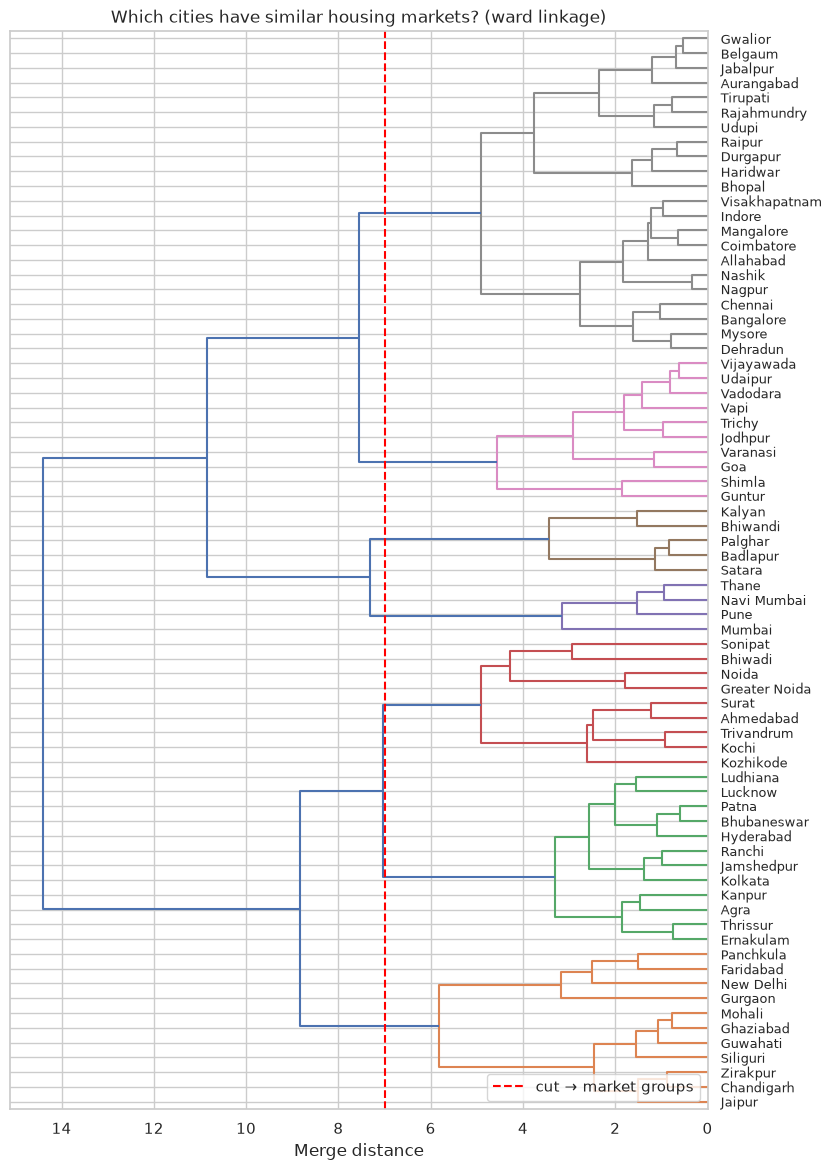

In [46]:
city_features = cities[market_cols].copy()
city_features["price_per_m2"] = np.log10(city_features["price_per_m2"])
X_cities = StandardScaler().fit_transform(city_features)

city_tree = linkage(X_cities, method="ward")

plt.figure(figsize=(9, 14))
dendrogram(city_tree, labels=cities.index.tolist(), orientation="left", leaf_font_size=9, color_threshold=7)
plt.axvline(7, color="red", linestyle="--", label="cut → market groups")
plt.title("Which cities have similar housing markets? (ward linkage)")
plt.xlabel("Merge distance")
plt.legend(loc="lower right")
save_fig("17_city_dendrogram")
plt.show()

In [47]:
from scipy.cluster.hierarchy import fcluster

cities["market"] = fcluster(city_tree, t=7, criterion="distance")   # cut the tree at height 7
print(f"Cutting at height 7 gives {cities['market'].nunique()} market groups")

market_profile = cities.groupby("market")[market_cols].median()
market_profile.insert(0, "cities", cities["market"].value_counts().sort_index())
market_profile["examples"] = cities.groupby("market").apply(
    lambda g: ", ".join(g.sort_values("listings", ascending=False).index[:4]))
market_profile.sort_values("price_per_m2", ascending=False)

Cutting at height 7 gives 7 market groups


,cities,price_per_m2,median_area_m2,median_bhk,share_furnished,share_new,median_total_floors,examples
market,,,,,,,,
4,4,"100,928.646",64.243,2.000,0.097,0.153,13.000,"Pune, Thane, Mumbai, Navi Mumbai"
3,9,"54,815.670",110.555,3.000,0.197,0.169,13.000,"Greater Noida, Ahmedabad, Surat, Noida"
2,12,"53,820.000",106.839,3.000,0.138,0.200,5.000,"Kolkata, Hyderabad, Ranchi, Lucknow"
1,11,"50,881.428",111.484,3.000,0.095,0.388,5.000,"Faridabad, Gurgaon, Jaipur, New Delhi"
7,22,"45,386.406",86.284,2.000,0.131,0.157,4.750,"Chennai, Bangalore, Visakhapatnam, Dehradun"
5,5,"44,175.456",51.097,1.000,0.067,0.070,7.000,"Kalyan, Palghar, Badlapur, Bhiwandi"
6,10,"42,071.094",92.903,2.000,0.246,0.095,4.500,"Vadodara, Goa, Vijayawada, Guntur"


Figure saved to figures/18_city_pca_biplot.png


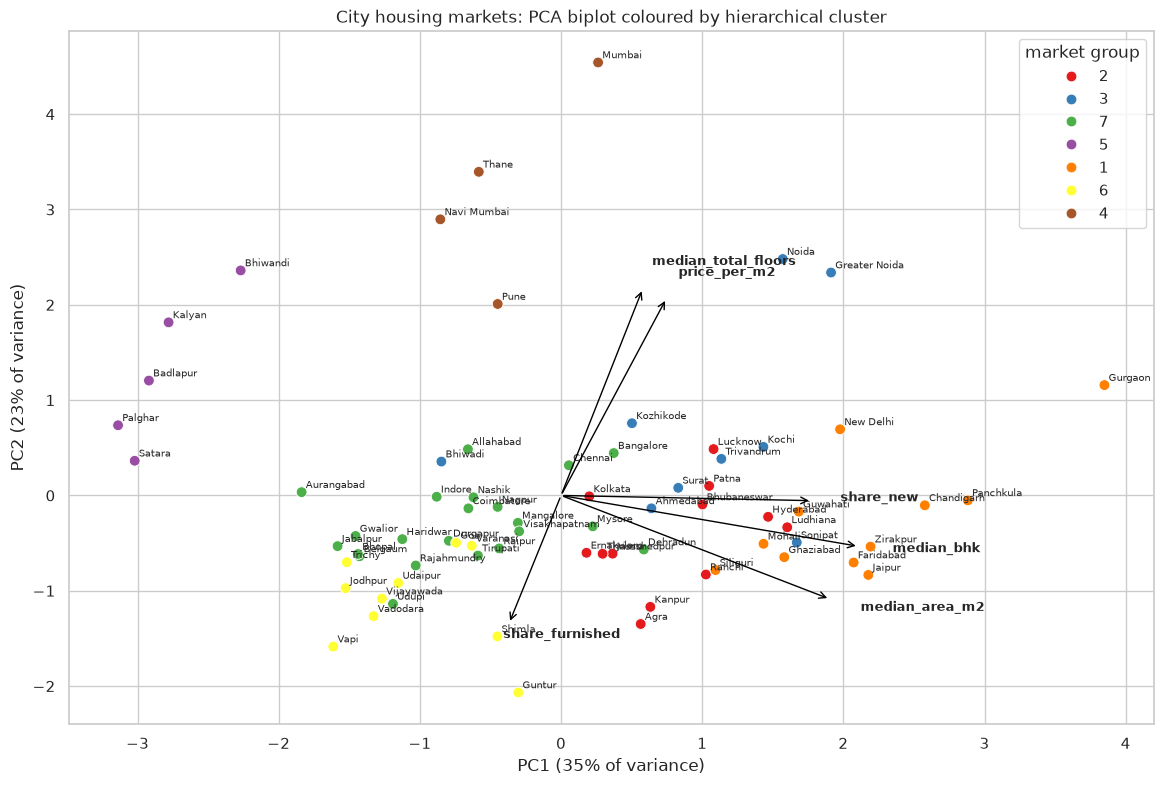

In [48]:
city_pca = PCA(n_components=2).fit(X_cities)
city_xy = city_pca.transform(X_cities)

fig, ax = plt.subplots(figsize=(14, 9))
sns.scatterplot(x=city_xy[:, 0], y=city_xy[:, 1], hue=cities["market"].astype(str), palette="Set1", s=60, ax=ax)
for (x, y), name in zip(city_xy, cities.index):
    ax.annotate(name, (x, y), fontsize=7, xytext=(3, 3), textcoords="offset points")

# Biplot arrows: how each original column points in the PCA plane
for name, (dx, dy) in zip(market_cols, city_pca.components_.T):
    ax.annotate("", xy=(dx * 3.5, dy * 3.5), xytext=(0, 0), arrowprops=dict(arrowstyle="->", color="black"))
    ax.text(dx * 3.9, dy * 3.9, name, fontsize=9, fontweight="bold")

explained = city_pca.explained_variance_ratio_
ax.set_xlabel(f"PC1 ({explained[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({explained[1]:.0%} of variance)")
ax.set_title("City housing markets: PCA biplot coloured by hierarchical cluster")
ax.legend(title="market group")
save_fig("18_city_pca_biplot")
plt.show()

Cutting the tree gives **7 market groups**, and they are recognisable:

| Group | Examples | Profile | A name |
|---|---|---|---|
| 4 | Mumbai, Thane, Navi Mumbai, Pune | By far the **highest price** (~₹1 lakh/m²), **small** flats (~64 m²), **tall** buildings (median 13 floors) | **Expensive high-rise metros** |
| 5 | Kalyan, Palghar, Badlapur, Bhiwandi | **Small 1-BHK** flats (~51 m²), low prices, few new projects | **Affordable satellite towns of Mumbai** |
| 3 | Noida, Greater Noida, Ahmedabad, Surat | Large 3-BHK flats in **tall** buildings, mid prices | **New high-rise suburbs** |
| 1 | Gurgaon, Faridabad, Jaipur, New Delhi | Large 3-BHK flats, **the most new construction** (~39% new) | **Growing Delhi-region markets** |
| 6 | Vadodara, Goa, Vijayawada, Guntur | Mid-sized flats, **the most furnished** listings, low-rise | **Low-rise, furnished markets** |
| 2 and 7 | Kolkata, Hyderabad, Lucknow / Chennai, Bangalore, Dehradun | Mid prices and sizes, low-rise | **"Average" markets**, separated mainly by flat size |

Notice that **geography appears by itself**: the Mumbai region forms two groups (core and periphery) and the Delhi region another, although the location was never a feature, only the market numbers.

The **biplot** explains the map: arrows show how each original column points in the PCA plane. **PC1** (left → right) grows with flat size, number of bedrooms and share of new construction; **PC2** (bottom → top) grows with **price per m²** and **building height**. Mumbai sits alone at the top: the most expensive and the tallest market.

⚠️ **Watch out:** remember the **sampling bias** from Day 1. The listings were scraped from one website, and some cities have thousands of listings while others have a few dozen. A city's "market" here is the market **as seen on that website**, not the official housing stock. And with ~70 rows, a single unusual city can change the tree: treat the groups as a starting point for discussion, not a fact.

# 8. From analysis to deliverable: save, reuse and publish

An analysis that lives only in a notebook helps nobody else. In this section we turn **Application B** into the deliverables of the Day 3 assignment (see [`Day_3/submissions/README.md`](../submissions/README.md)):

1. a **model** that assigns any new day to one of the four profiles, with a **model card**;
2. a **dataset**: the daily profiles with their clusters, with a **dataset card**.

This folder (`Day_3/docs/`) is organised exactly like your submission repository, so you can use it as a worked example:

```
Day_3/docs/
├── data/                                    # downloaded and processed data
├── dataset/
│   ├── README.md                            # the dataset card
│   └── daily_load_profiles_clustered.csv    # the published table (section 8.2)
├── figures/                                 # exported plots
├── models/
│   ├── README.md                            # the model card
│   └── model.joblib                         # the fitted pipeline (section 8.1)
└── application_of_unsupervised_learning.ipynb
```

Why Application B? Because its model can **assign new examples**: K-Means has `.predict()`, and the pipeline normalises a raw day by itself. A utility or a building manager could feed it tomorrow's meter readings.

## 8.1 Save the model, reload it, use it on new days

We save the **whole pipeline** (normaliser + K-Means) with `joblib`, as on Day 2. The cluster numbers mean nothing by themselves, so we also keep the **names** from our interpretation in section 5.1: they go into the model card, where users will find them.

In [49]:
CLUSTER_NAMES = {
    0: "workday, home in the morning",
    1: "at home all day",
    2: "workday, empty house",
    3: "nobody home",
}

model_path = MODEL_DIR / "model.joblib"
joblib.dump(profile_model, model_path)
print(f"Saved {model_path} ({model_path.stat().st_size / 1024:.0f} KB)")

# Reload it, as a user of the model would
loaded_model = joblib.load(model_path)

# Two hand-made days, in kW for each hour 0..23
base = np.full(24, 0.3)                                   # fridge and standby only
evening_person = base.copy()
evening_person[[6, 7]] = [1.2, 1.5]                       # quick breakfast
evening_person[[18, 19, 20, 21, 22]] = [1.5, 2.5, 3.0, 2.8, 1.5]   # cooking, washing, TV

new_days = pd.DataFrame([base, evening_person], columns=hour_cols, index=["holiday day", "evening-peak workday"])
for name, cluster in zip(new_days.index, loaded_model.predict(new_days)):
    print(f"{name:>22}: profile {cluster} = {CLUSTER_NAMES[cluster]}")

Saved models/model.joblib (8 KB)
           holiday day: profile 3 = nobody home
  evening-peak workday: profile 2 = workday, empty house


A day with only the base load is recognised as **"nobody home"**, and a day with a small breakfast and a big evening peak as **"workday, empty house"**. The model only needs the 24 hourly values in kW; the normalisation happens inside the pipeline.

⚠️ **Watch out:** the model always answers with one of the four profiles, even for a day that looks like none of them (an office, a day with an electric car charging at night). K-Means has no "I don't know" (DBSCAN's noise label is the closest thing). This limitation goes into the model card.

## 8.2 Export the dataset

**Can we publish this data?** The dataset is the main deliverable of the Day 3 assignment, so we check it against [section 5.1 of the submission brief](../submissions/README.md#51-the-dataset-your-main-deliverable):

| Question | Answer |
|---|---|
| Is our version **new**? | Yes: 2 million minute readings became 1,411 **daily profiles** (hourly averages, a quality filter that drops hours with fewer than 45 valid minutes and incomplete days), with **engineered features** (daily kWh, calendar), **cluster labels and names**, and the **2D coordinates** of the PCA, t-SNE and UMAP maps. That is feature engineering, not a copy with renamed columns. |
| Does the **licence** allow it? | Yes: the original is published under **CC BY 4.0**, which allows sharing derived data **with attribution** (credited in the dataset card). |
| **Personal data**? | No names or addresses: one anonymous household's total consumption. |

So we may publish it, and we export one table with everything a reader needs:

In [50]:
published = daily.round(4).copy()
published["daily_kwh"] = daily_total_kwh.round(3)
published["weekday"] = daily.index.day_name()
published["weekend"] = calendar["weekend"]
published["month"] = calendar["month"]
published["season"] = calendar["season"]
published["cluster"] = calendar["profile"]
published["cluster_name"] = calendar["profile"].map(CLUSTER_NAMES)
# The 2D coordinates of section 5.3, so anyone can redraw the maps without recomputing them
for method, prefix in [("PCA", "pca"), ("t-SNE", "tsne"), ("UMAP", "umap")]:
    published[f"{prefix}_x"] = views[method][:, 0].round(4)
    published[f"{prefix}_y"] = views[method][:, 1].round(4)

dataset_path = DATASET_DIR / "daily_load_profiles_clustered.csv"
published.to_csv(dataset_path, index_label="date")
print(f"Saved {dataset_path}: {published.shape[0]:,} rows x {published.shape[1] + 1} columns")
published.head(3)

Saved dataset/daily_load_profiles_clustered.csv: 1,411 rows x 38 columns


,h00,h01,h02,h03,h04,h05,h06,h07,h08,h09,h10,h11,h12,h13,h14,h15,h16,h17,h18,h19,h20,h21,h22,h23,daily_kwh,weekday,weekend,month,season,cluster,cluster_name,pca_x,pca_y,tsne_x,tsne_y,umap_x,umap_y
date,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2006-12-17,1.883,3.349,1.587,1.662,2.216,1.997,1.303,1.620,1.891,2.549,3.629,2.471,1.916,1.661,2.093,2.985,3.326,3.407,3.697,2.908,3.361,3.041,1.518,0.438,56.508,Sunday,True,12,winter,3,nobody home,-0.052,-0.020,-37.201,-5.150,7.361,10.389
2006-12-18,0.276,0.313,0.284,0.310,1.026,0.293,0.610,2.450,2.082,1.629,1.310,1.562,1.756,1.682,1.733,1.784,1.949,2.155,2.402,2.615,3.051,2.170,1.739,1.547,36.730,Monday,False,12,winter,1,at home all day,-0.006,-0.031,-9.683,4.211,8.751,7.588
2006-12-19,0.837,0.353,0.327,0.308,0.328,0.307,0.796,1.786,3.879,1.618,0.437,2.322,0.431,0.300,0.302,0.421,1.372,2.111,2.205,1.842,2.941,1.443,0.720,0.384,27.770,Tuesday,False,12,winter,0,"workday, home in the morning",0.037,0.005,6.838,15.863,9.106,5.693


A dataset card is easier to trust with a few pictures. We draw them **from the published table itself** (not from the notebook's variables), so the card shows exactly what a user will download, and save them into `dataset/` next to the card.

Figure saved to figures/dataset_average_days.png


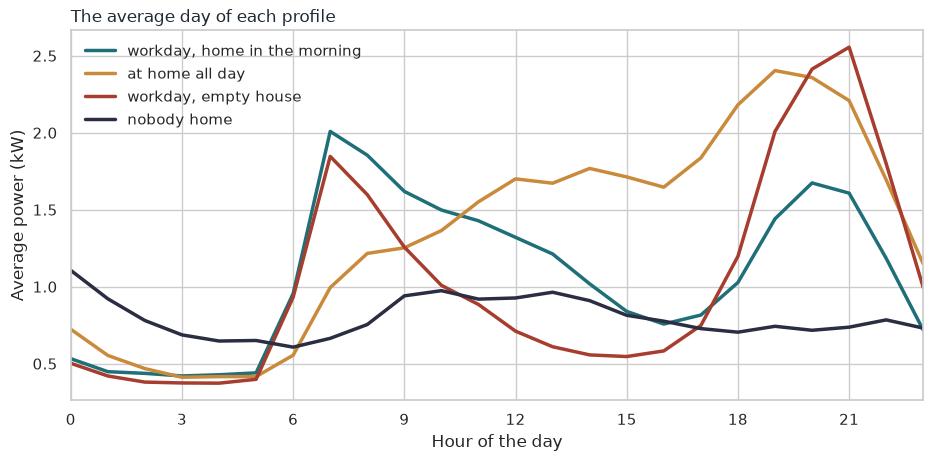

Figure saved to figures/dataset_clusters_overview.png


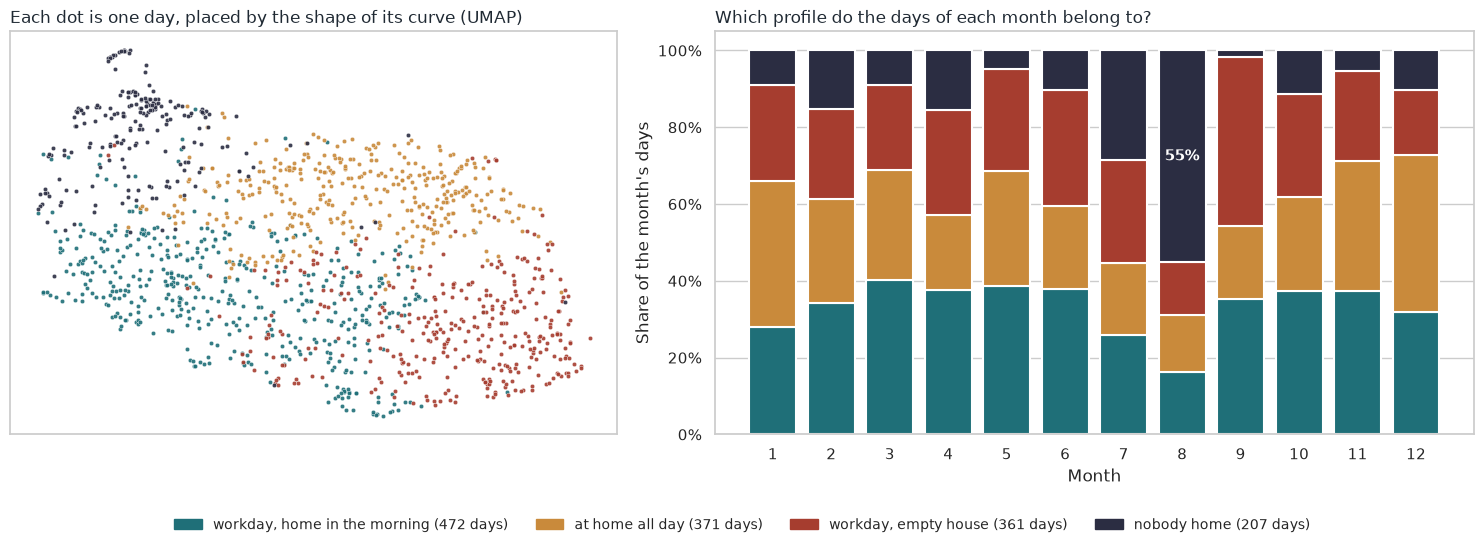

In [51]:
# One fixed colour per profile, the same in every plot of the card
PROFILE_COLORS = {"workday, home in the morning": "#1F6F78", "at home all day": "#C98A3B",
                  "workday, empty house": "#A63D2F", "nobody home": "#2B2D42"}
INK, MUTED_INK = "#1F2933", "#5B646E"
order = list(CLUSTER_NAMES.values())


def save_card_figure(name):
    # Save into figures/ (like every figure) AND into dataset/ (uploaded with the card)
    save_fig(name)
    plt.savefig(DATASET_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


# 1. The average day of each profile, in kW: shape AND volume
average_day = published.groupby("cluster_name")[hour_cols].mean().loc[order]
fig, ax = plt.subplots(figsize=(11, 4.8))
for name, values in average_day.iterrows():
    ax.plot(hours, values.values, color=PROFILE_COLORS[name], lw=2.5, label=name)
ax.set_xlim(0, 23)
ax.set_xticks(range(0, 24, 3))
ax.set_xlabel("Hour of the day")
ax.set_ylabel("Average power (kW)")
ax.set_title("The average day of each profile", loc="left", color=INK)
ax.legend(loc="upper left", frameon=False)
save_card_figure("dataset_average_days")
plt.show()

# 2. How the clustering behaves: the days on the UMAP map, and the profiles through the year
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
for name in order:
    part = published[published["cluster_name"] == name]
    ax.scatter(part["umap_x"], part["umap_y"], s=10, alpha=0.9, color=PROFILE_COLORS[name],
               edgecolor="white", linewidth=0.3, label=f"{name} ({len(part)} days)")
ax.set_xticks([])
ax.set_yticks([])
ax.set_title("Each dot is one day, placed by the shape of its curve (UMAP)", loc="left", color=INK, fontsize=12)

ax = axes[1]
month_shares = pd.crosstab(published["month"], published["cluster_name"], normalize="index")[order]
bottom = np.zeros(12)
for name in order:
    ax.bar(month_shares.index, month_shares[name], bottom=bottom, color=PROFILE_COLORS[name],
           edgecolor="white", linewidth=1.5, width=0.8)
    bottom += month_shares[name].values
august_holiday = month_shares.loc[8, "nobody home"]
ax.text(8, 1 - august_holiday / 2, f"{august_holiday:.0%}", ha="center", va="center", color="white",
        fontsize=11, fontweight="bold")          # the August holidays, labelled on the bar itself
ax.set_xticks(range(1, 13))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("Month")
ax.set_ylabel("Share of the month's days")
ax.set_title("Which profile do the days of each month belong to?", loc="left", color=INK, fontsize=12)
ax.grid(axis="x", visible=False)
handles = [plt.matplotlib.patches.Patch(color=PROFILE_COLORS[name],
                                       label=f"{name} ({(published['cluster_name'] == name).sum()} days)")
           for name in order]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, fontsize=10)
plt.tight_layout(rect=(0, 0.07, 1, 1))           # leave room for the shared legend
save_card_figure("dataset_clusters_overview")
plt.show()

## 8.3 The cards, and publishing on Hugging Face

The files are only half of the deliverable; the other half is the documentation that lets a stranger use them. Both cards are written by hand, next to the files they describe:

- [`models/README.md`](models/README.md), the **model card**: what the model does, the input columns, **the table of the four named profiles**, how they were found, the stability check, the limitations and a code example.
- [`dataset/README.md`](dataset/README.md), the **dataset card**: the source and its licence (attribution), **what we changed**, every column, the limitations and how to load it.

Publishing follows [section 5 of the submission brief](../submissions/README.md#5-publish-on-hugging-face). From this folder:

```bash
# the model
hf repos create iaac-maai/day3-example-load-profiles --type model --exist-ok
hf upload iaac-maai/day3-example-load-profiles models . --commit-message "Upload profile model and model card"

# the dataset (note --type dataset in BOTH commands)
hf repos create iaac-maai/day3-example-daily-load-profiles --type dataset --exist-ok
hf upload iaac-maai/day3-example-daily-load-profiles dataset . --type dataset --commit-message "Upload dataset and dataset card"
```

💡 **Tip:** open the two cards side by side with this notebook. Every number in them comes from an output above: that is how you keep documentation honest.

# 9. Summary: which method when?

| You want to… | Try first | Then consider |
|---|---|---|
| Group examples, k roughly known, many rows | **K-Means** | Hierarchical on a sample to check k |
| Group examples and **explain** the grouping | **Hierarchical** + dendrogram | K-Means for large data |
| Find objects of **any shape**, or separate noise | **DBSCAN** | HDBSCAN if densities differ |
| Understand which columns vary together / compress columns | **PCA** (loadings + explained variance) | |
| **See** high-dimensional data in 2D | **PCA** first, then **UMAP** or **t-SNE** | |
| Prepare features for a supervised model | **PCA** | UMAP (`.transform` works on new data) |

### Checklist for a good unsupervised analysis
- [ ] **Scale** the features (unless they share a unit, like x, y, z in metres).
- [ ] Choose the features **on purpose**: they define what "similar" means.
- [ ] Try **several k** (or `eps`) and look at the elbow / silhouette / k-distance plot.
- [ ] Check **stability**: change `random_state` or drop a few rows; good clusters survive.
- [ ] **Interpret** every cluster: profile it with averages, and with variables you did **not** cluster on.
- [ ] **Name** the clusters ("weekend days", "compact two-storey shapes"). If you can't name a cluster, question it.
- [ ] Don't over-read **t-SNE / UMAP** pictures: neighbours matter, sizes and gaps don't.
- [ ] Remember the limits of the data (simulated? biased sample?).

# 10. Your turn

Pick at least one exercise. Write your answers in markdown cells: **the interpretation matters more than the code.**

**Exercise 1 – Volume instead of shape.** Repeat the load-profile clustering (section 5) on the **raw** `daily` table instead of the normalised `shapes_24h`. Plot the centroids and the month heatmap again. What do the clusters separate now? Which version would you give to a utility designing time-of-use tariffs, and which to someone sizing a heat pump?

**Exercise 2 – Tune DBSCAN on a noisier site.** Regenerate the point cloud with 10 times more noise points (`1200` instead of `120`) and trees closer together (e.g. `x` positions `10, 15, 20, 25`). Use the k-distance plot to pick a new `eps`. Does DBSCAN still separate the trees? What happens with `eps = 0.8` and `eps = 3`?

**Exercise 3 – Unsupervised meets supervised.** Take the Day 2 energy classification (classes A / B / C from the heating load) and build a pipeline `StandardScaler → PCA(n_components=…) → LogisticRegression`. Compare the cross-validated macro-F1 for 2, 3, 5 and 8 components. How many components do you need? Relate the answer to the explained-variance plot of section 4.1.

```python
# Starter for exercise 3
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

energy_class = pd.cut(energy["heating_load"], bins=[0, 15, 30, np.inf], labels=["A", "B", "C"])
for n in [2, 3, 5, 8]:
    pipe = make_pipeline(StandardScaler(), PCA(n_components=n), LogisticRegression(max_iter=1000))
    scores = cross_val_score(pipe, energy[design_cols], energy_class, cv=5, scoring="f1_macro")
    print(n, scores.mean().round(3))
```

In [52]:
# Your code here

# 11. Conclusions and next steps

### Key findings
- **Scaling and feature choice define similarity.** In the toy example, raw numbers mixed blocks and towers; scaled numbers separated them. In Application A, clustering all 8 design parameters gave no clear groups (silhouette ≈ 0.2), while geometry alone recovered the **12 building shapes perfectly** (silhouette = ARI = 1.0).
- **PCA explains the structure of a dataset.** The 8 parameters of the energy dataset really contain 5 dimensions: one shape axis plus independently varied glazing and orientation. Shape families found without the loads had clearly different heating demands (from ~12 to ~36 kWh/m²·year).
- **Real data is a continuum, and clusters are still useful.** The 1,411 daily load curves had a low silhouette (~0.1) for every k, yet 4 clusters gave interpretable typical days: two kinds of workday, an "at home all day" profile (mostly weekends and winter) and an "empty house" profile that contains **55% of all August days**. The profiles are reproducible (ARI ≈ 0.98 across seeds) but are one way of cutting a continuum: ward clustering cuts it differently (ARI ≈ 0.34).
- **The shape of the clusters decides the algorithm.** On the point cloud, K-Means (ARI ≈ 0.53) split the L-shaped building and merged trees; DBSCAN (ARI ≈ 0.99) found the 6 objects and the noise without being told how many.
- **Dendrograms tell a story.** Hierarchical clustering of 73 Indian cities found 7 housing markets, with the Mumbai and Delhi regions emerging without any location information.

### Limitations
- Application A uses **simulated** buildings on a design grid: real building stocks are messier and have no perfect clusters.
- Application B is **one** household; profiles of offices, schools or a whole district would look different.
- The point cloud is **synthetic** and clean: real scans have occlusions, uneven density and millions of points.
- Application D inherits the **sampling bias** of the scraped listings (Day 1).
- Every clustering here depends on choices (features, scaling, k, `eps`); a different reasonable choice gives different groups. Always report your choices.

### Your deliverable
The Day 3 assignment is described in [`Day_3/submissions/README.md`](../submissions/README.md): a structured GitHub repository with your analysis, your model on Hugging Face with a **model card** and, if your dataset is your own work, the dataset with a **dataset card**. This folder is a complete worked example: compare the structure, [`models/README.md`](models/README.md) and [`dataset/README.md`](dataset/README.md) with your own.

### Next: Day 4
So far every example was a row in a table. On Day 4 we move to **images**: neural networks, image processing with **OpenCV** and object detection with **YOLO**, to find windows, facade elements and safety equipment in pictures. Some ideas from today come back: segmentation, and the fact that a deep network also learns its own compressed representation of the data, a kind of learned dimensionality reduction.

### References
- scikit-learn user guide: [Clustering](https://scikit-learn.org/stable/modules/clustering.html) and [Decomposing signals in components (PCA)](https://scikit-learn.org/stable/modules/decomposition.html)
- UMAP documentation: [How to use UMAP](https://umap-learn.readthedocs.io/)
- Wattenberg, Viégas & Johnson (2016), [How to Use t-SNE Effectively](https://distill.pub/2016/misread-tsne/), Distill
- [Clustering Visualizer](https://clustering-visualizer.web.app/): watch K-Means, hierarchical clustering, DBSCAN and Mean Shift group points you draw yourself
- Coenen & Pearce (Google PAIR), [Understanding UMAP](https://pair-code.github.io/understanding-umap/): an interactive comparison of UMAP and t-SNE
- Géron, A. (2022), *Hands-On Machine Learning with Scikit-Learn, Keras, and TensorFlow* (3rd ed.), chapters 8 (dimensionality reduction) and 9 (unsupervised learning)
- Tsanas, A. & Xifara, A. (2012), *Accurate quantitative estimation of energy performance of residential buildings using statistical machine learning tools*, Energy and Buildings 49
- Hebrail, G. & Berard, A. (2006), *Individual Household Electric Power Consumption* [Dataset], UCI Machine Learning Repository, CC BY 4.0, https://doi.org/10.24432/C58K54